# Ejercicio 2 — Predicción de Abandono de Clientes (Customer Churn)
## Empresa de Telecomunicaciones · Telco Customer Churn Dataset

**Objetivo:** construir y comparar 5 modelos de clasificación supervisada (Logistic Regression, KNN, SVM, Decision Tree y Naive Bayes) para predecir qué clientes abandonarán la empresa (`Churn = Yes`), seleccionar el mejor con justificación estadística (ANOVA + Tukey) y usarlo en un sistema de predicción de nuevos clientes.

**Dataset:** [Telco Customer Churn (Kaggle – blastchar)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Se carga desde el mirror público de IBM (mismo archivo), así el cuaderno corre en Colab sin credenciales de Kaggle.

### Contenido
1. Configuración del entorno
2. Comprensión del negocio
3. Carga de datos
4. Análisis exploratorio de datos (EDA)
5. Preprocesamiento (limpieza, codificación, escalamiento, división, balanceo)
6. Entrenamiento y evaluación de modelos
7. Fortalezas y debilidades de cada modelo
8. Validación cruzada, ANOVA y prueba de hipótesis
9. Selección del mejor modelo
10. Sistema de predicción de nuevos clientes
11. Preguntas de interpretación de métricas
12. Preguntas de análisis crítico
13. Conclusiones empresariales
14. Despliegue web (Streamlit)

## 1. Configuración del entorno
Colab ya trae `scikit-learn`, `pandas`, `seaborn` y `statsmodels`. Se instala `imbalanced-learn` (SMOTE) por si no está disponible.

In [1]:
%pip install -q imbalanced-learn statsmodels

Note: you may need to restart the kernel to use updated packages.


C:\Users\JAMN\churn-telco\.venv-colab\Scripts\python.exe: No module named pip


In [2]:
# Librerías generales
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Estadística
from scipy.stats import f_oneway, levene, shapiro
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Machine Learning
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, ConfusionMatrixDisplay)

# Balanceo de clases
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
print("Librerías cargadas correctamente")

Librerías cargadas correctamente


## 2. Comprensión del Negocio

### 2.1 ¿Por qué es importante predecir el abandono de clientes?

- **Retener cuesta menos que adquirir.** En telecomunicaciones, conseguir un cliente nuevo cuesta varias veces más (publicidad, comisiones, subsidio de equipos, instalación) que conservar uno actual.
- **Permite pasar de una gestión reactiva a una proactiva.** Si la empresa se entera del abandono cuando el cliente ya pidió la baja, casi siempre es tarde. Un modelo predictivo detecta la señal de riesgo *antes* y da tiempo para actuar.
- **Prioriza recursos limitados.** No se puede llamar ni ofrecer descuento a los 7.000 clientes; el modelo ordena a los clientes por probabilidad de abandono para concentrar el esfuerzo en quienes realmente están en riesgo.
- **Revela las causas del abandono.** Variables como tipo de contrato, permanencia, soporte técnico o método de pago muestran *por qué* se van los clientes, lo que permite corregir problemas del producto o del servicio.
- **En este dataset el problema es grande:** cerca del **26,5 %** de los clientes abandonó (ver EDA), es decir, 1 de cada 4.

### 2.2 ¿Qué impacto económico tiene el churn?

- **Pérdida directa de ingresos recurrentes:** cada cliente que se va deja de pagar su factura mensual. En este dataset los clientes que abandonaron representaban una parte desproporcionada de la facturación mensual (se cuantifica en la sección 4.7).
- **Pérdida del valor de vida del cliente (CLV):** no solo se pierde la factura de este mes, sino todos los ingresos futuros que ese cliente habría generado.
- **Costo de adquisición hundido (CAC):** el dinero invertido en captar al cliente no se recupera si se va antes de tiempo, y hay que gastar de nuevo para reemplazarlo.
- **Efectos indirectos:** mala reputación y recomendaciones negativas (boca a boca), menos ventas cruzadas (*cross-selling*) y menor participación de mercado frente a la competencia.
- **Efecto compuesto:** una pequeña reducción del churn (por ejemplo, 5 puntos porcentuales) tiene un gran impacto en la rentabilidad, porque los clientes retenidos siguen pagando mes a mes.

### 2.3 ¿Cómo puede Machine Learning apoyar estrategias de marketing?

- **Segmentación por riesgo:** el modelo asigna a cada cliente una probabilidad de abandono, con la que se arman segmentos (riesgo alto, medio y bajo) para tratarlos de forma distinta.
- **Campañas focalizadas:** en vez de campañas masivas, marketing dirige ofertas solo a los clientes con alta probabilidad de abandono, lo que reduce costos y mejora la tasa de respuesta.
- **Ofertas personalizadas según la causa:** si el riesgo viene de un contrato mes a mes, se ofrece migrar a un contrato anual con descuento; si viene de la falta de soporte técnico, se ofrece soporte gratis por unos meses.
- **Optimización del presupuesto:** combinando la probabilidad de abandono con el valor del cliente (factura mensual), se priorizan los clientes más valiosos con mayor riesgo.
- **Medición de resultados:** se pueden hacer pruebas A/B (grupo con oferta contra grupo de control) para medir si la campaña realmente redujo el churn.
- **Monitoreo continuo:** el modelo puede recalcular el riesgo cada mes y alertar cuando un cliente cambia de segmento.

### 2.4 ¿Qué departamentos de una empresa usarían este sistema?

| Departamento | Uso del sistema |
|---|---|
| **Marketing** | Diseñar campañas de retención y fidelización dirigidas a clientes de alto riesgo. |
| **Atención al cliente / Retención (call center)** | Priorizar llamadas proactivas y saber qué ofrecer a cada cliente. |
| **Ventas / Comercial** | Proponer upgrades o migraciones a contratos de 1 o 2 años a clientes con riesgo. |
| **Finanzas** | Proyectar ingresos, estimar pérdidas por churn y calcular el retorno de las campañas de retención. |
| **Producto y Servicio técnico** | Detectar qué servicios (fibra óptica, falta de soporte) se asocian a más abandono y mejorarlos. |
| **Dirección / Business Intelligence** | Seguir indicadores (KPI) de churn y tomar decisiones estratégicas. |
| **TI / Ciencia de Datos** | Mantener, monitorear y reentrenar el modelo en producción. |

## 3. Carga de datos

In [3]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_raw = pd.read_csv(URL)

print(f"Filas: {df_raw.shape[0]} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 7043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Diccionario de variables

| Grupo | Variables | Descripción |
|---|---|---|
| Identificación | `customerID` | ID del cliente (no aporta información predictiva). |
| Demográficas | `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Género, adulto mayor, tiene pareja, tiene dependientes. |
| Tiempo de permanencia | `tenure` | Meses que el cliente lleva en la empresa. |
| Servicios contratados | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Telefonía, internet (DSL / Fiber optic / No) y servicios adicionales. |
| Contrato y pago | `Contract`, `PaperlessBilling`, `PaymentMethod` | Tipo de contrato, factura electrónica y método de pago. |
| Facturación | `MonthlyCharges`, `TotalCharges` | Cargo mensual y cargo total acumulado. |
| **Objetivo** | **`Churn`** | **Yes** = el cliente abandonó · **No** = el cliente continúa. |

## 4. Análisis Exploratorio de Datos (EDA)
### 4.1 Estructura y tipos de datos

In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 4.2 Calidad de datos: nulos, duplicados y valores anómalos

In [5]:
print("Valores nulos por columna (NaN):", int(df_raw.isnull().sum().sum()))
print("Filas duplicadas:", df_raw.duplicated().sum())
print("customerID duplicados:", df_raw["customerID"].duplicated().sum())

# TotalCharges debería ser numérica pero se leyó como texto: hay valores en blanco
blancos = df_raw["TotalCharges"].astype(str).str.strip() == ""
print(f"\nTotalCharges en blanco: {blancos.sum()}")
print("tenure de esos clientes:", df_raw.loc[blancos, "tenure"].unique())
df_raw.loc[blancos, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Valores nulos por columna (NaN): 0
Filas duplicadas: 0
customerID duplicados: 0

TotalCharges en blanco: 11
tenure de esos clientes: [0]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Hallazgo:** no hay `NaN` explícitos, pero `TotalCharges` llegó como texto porque tiene **11 valores en blanco**. Todos esos clientes tienen `tenure = 0`, es decir, son clientes nuevos que todavía no recibieron su primera factura. Por eso su cargo total real es 0. Se corrige en el preprocesamiento.

Para poder graficar, en el EDA se usa una copia con `TotalCharges` convertida a número.

In [6]:
df_eda = df_raw.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce").fillna(0)
df_eda["Churn_bin"] = (df_eda["Churn"] == "Yes").astype(int)
df_eda["SeniorCitizen"] = df_eda["SeniorCitizen"].map({0: "No", 1: "Yes"})

NUM_EDA = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_EDA = [c for c in df_eda.columns if c not in NUM_EDA + ["customerID", "Churn", "Churn_bin"]]
print("Numéricas  :", NUM_EDA)
print("Categóricas:", CAT_EDA)
df_eda[NUM_EDA].describe().round(2)

Numéricas  : ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


### 4.3 Distribución de la variable objetivo (Churn)

       Clientes      %
Churn                 
No         5174  73.46
Yes        1869  26.54


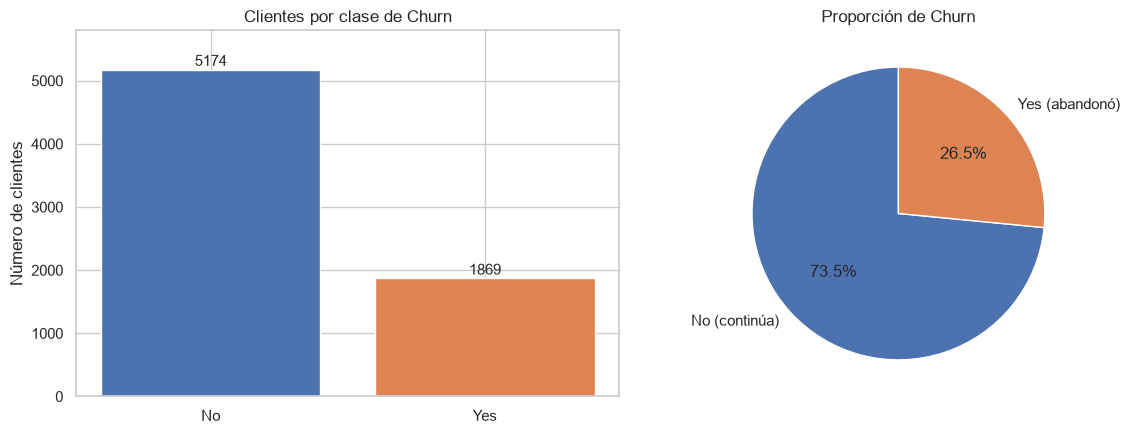

In [7]:
conteo = df_eda["Churn"].value_counts()
porcentaje = df_eda["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Clientes": conteo, "%": porcentaje.round(2)}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colores = ["#4C72B0", "#DD8452"]
axes[0].bar(conteo.index, conteo.values, color=colores)
for i, v in enumerate(conteo.values):
    axes[0].text(i, v + 60, f"{v}", ha="center", fontsize=11)
axes[0].set_title("Clientes por clase de Churn")
axes[0].set_ylabel("Número de clientes")
axes[0].set_ylim(0, conteo.max() * 1.12)
axes[1].pie(conteo.values, labels=["No (continúa)", "Yes (abandonó)"], autopct="%1.1f%%",
            colors=colores, startangle=90, wedgeprops={"edgecolor": "white"})
axes[1].set_title("Proporción de Churn")
plt.tight_layout()
plt.show()

**Las clases están desbalanceadas:** ~73,5 % *No* frente a ~26,5 % *Yes* (aprox. 2,8 : 1). Un modelo que siempre prediga "No" tendría un Accuracy de ~73,5 % sin detectar ni un solo cliente que abandona. Por eso:
1. La división entrenamiento/prueba se hace **estratificada**.
2. Se **balancea** el conjunto de entrenamiento con **SMOTE** (sección 5.5).
3. Se evalúa con **Recall, Precision, F1 y ROC-AUC**, no solo con Accuracy.

### 4.4 Variables numéricas según Churn

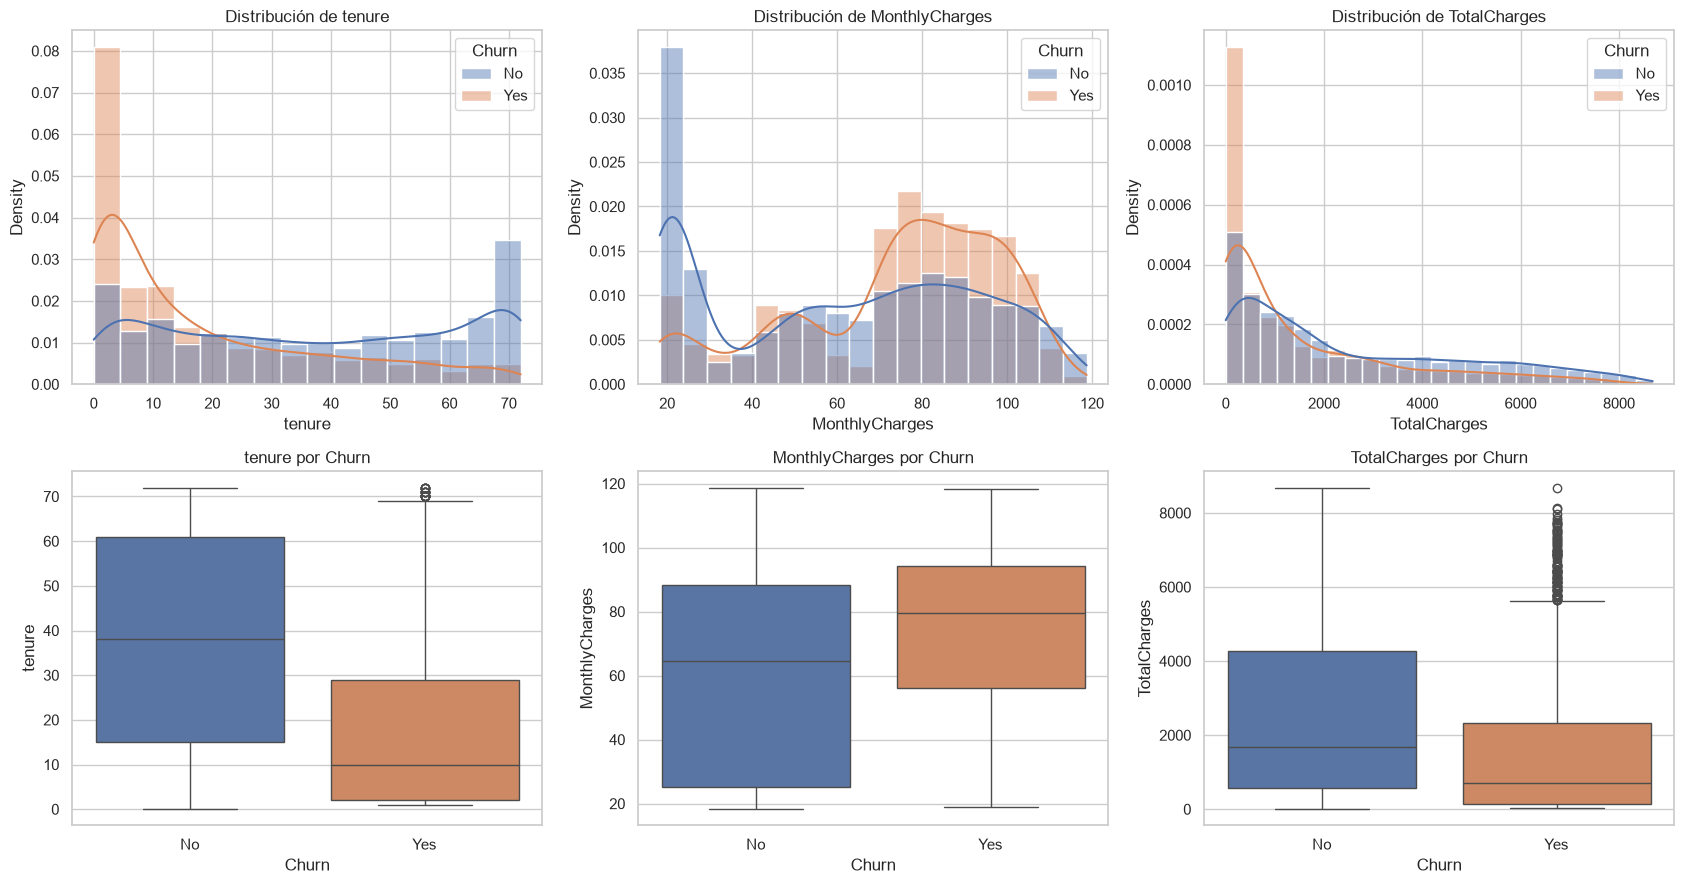

,tenure,MonthlyCharges,TotalCharges
Mediana por Churn,,,
No,38.0,64.43,1679.52
Yes,10.0,79.65,703.55


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for i, col in enumerate(NUM_EDA):
    sns.histplot(data=df_eda, x=col, hue="Churn", kde=True, stat="density",
                 common_norm=False, ax=axes[0, i], palette=colores, alpha=0.45)
    axes[0, i].set_title(f"Distribución de {col}")
    sns.boxplot(data=df_eda, x="Churn", y=col, ax=axes[1, i], palette=colores)
    axes[1, i].set_title(f"{col} por Churn")
plt.tight_layout()
plt.show()

df_eda.groupby("Churn")[NUM_EDA].median().round(2).rename_axis("Mediana por Churn")

### 4.5 Tasa de abandono por variable categórica
La línea roja punteada marca la tasa global de churn. Las barras por encima de esa línea son categorías de **mayor riesgo**.

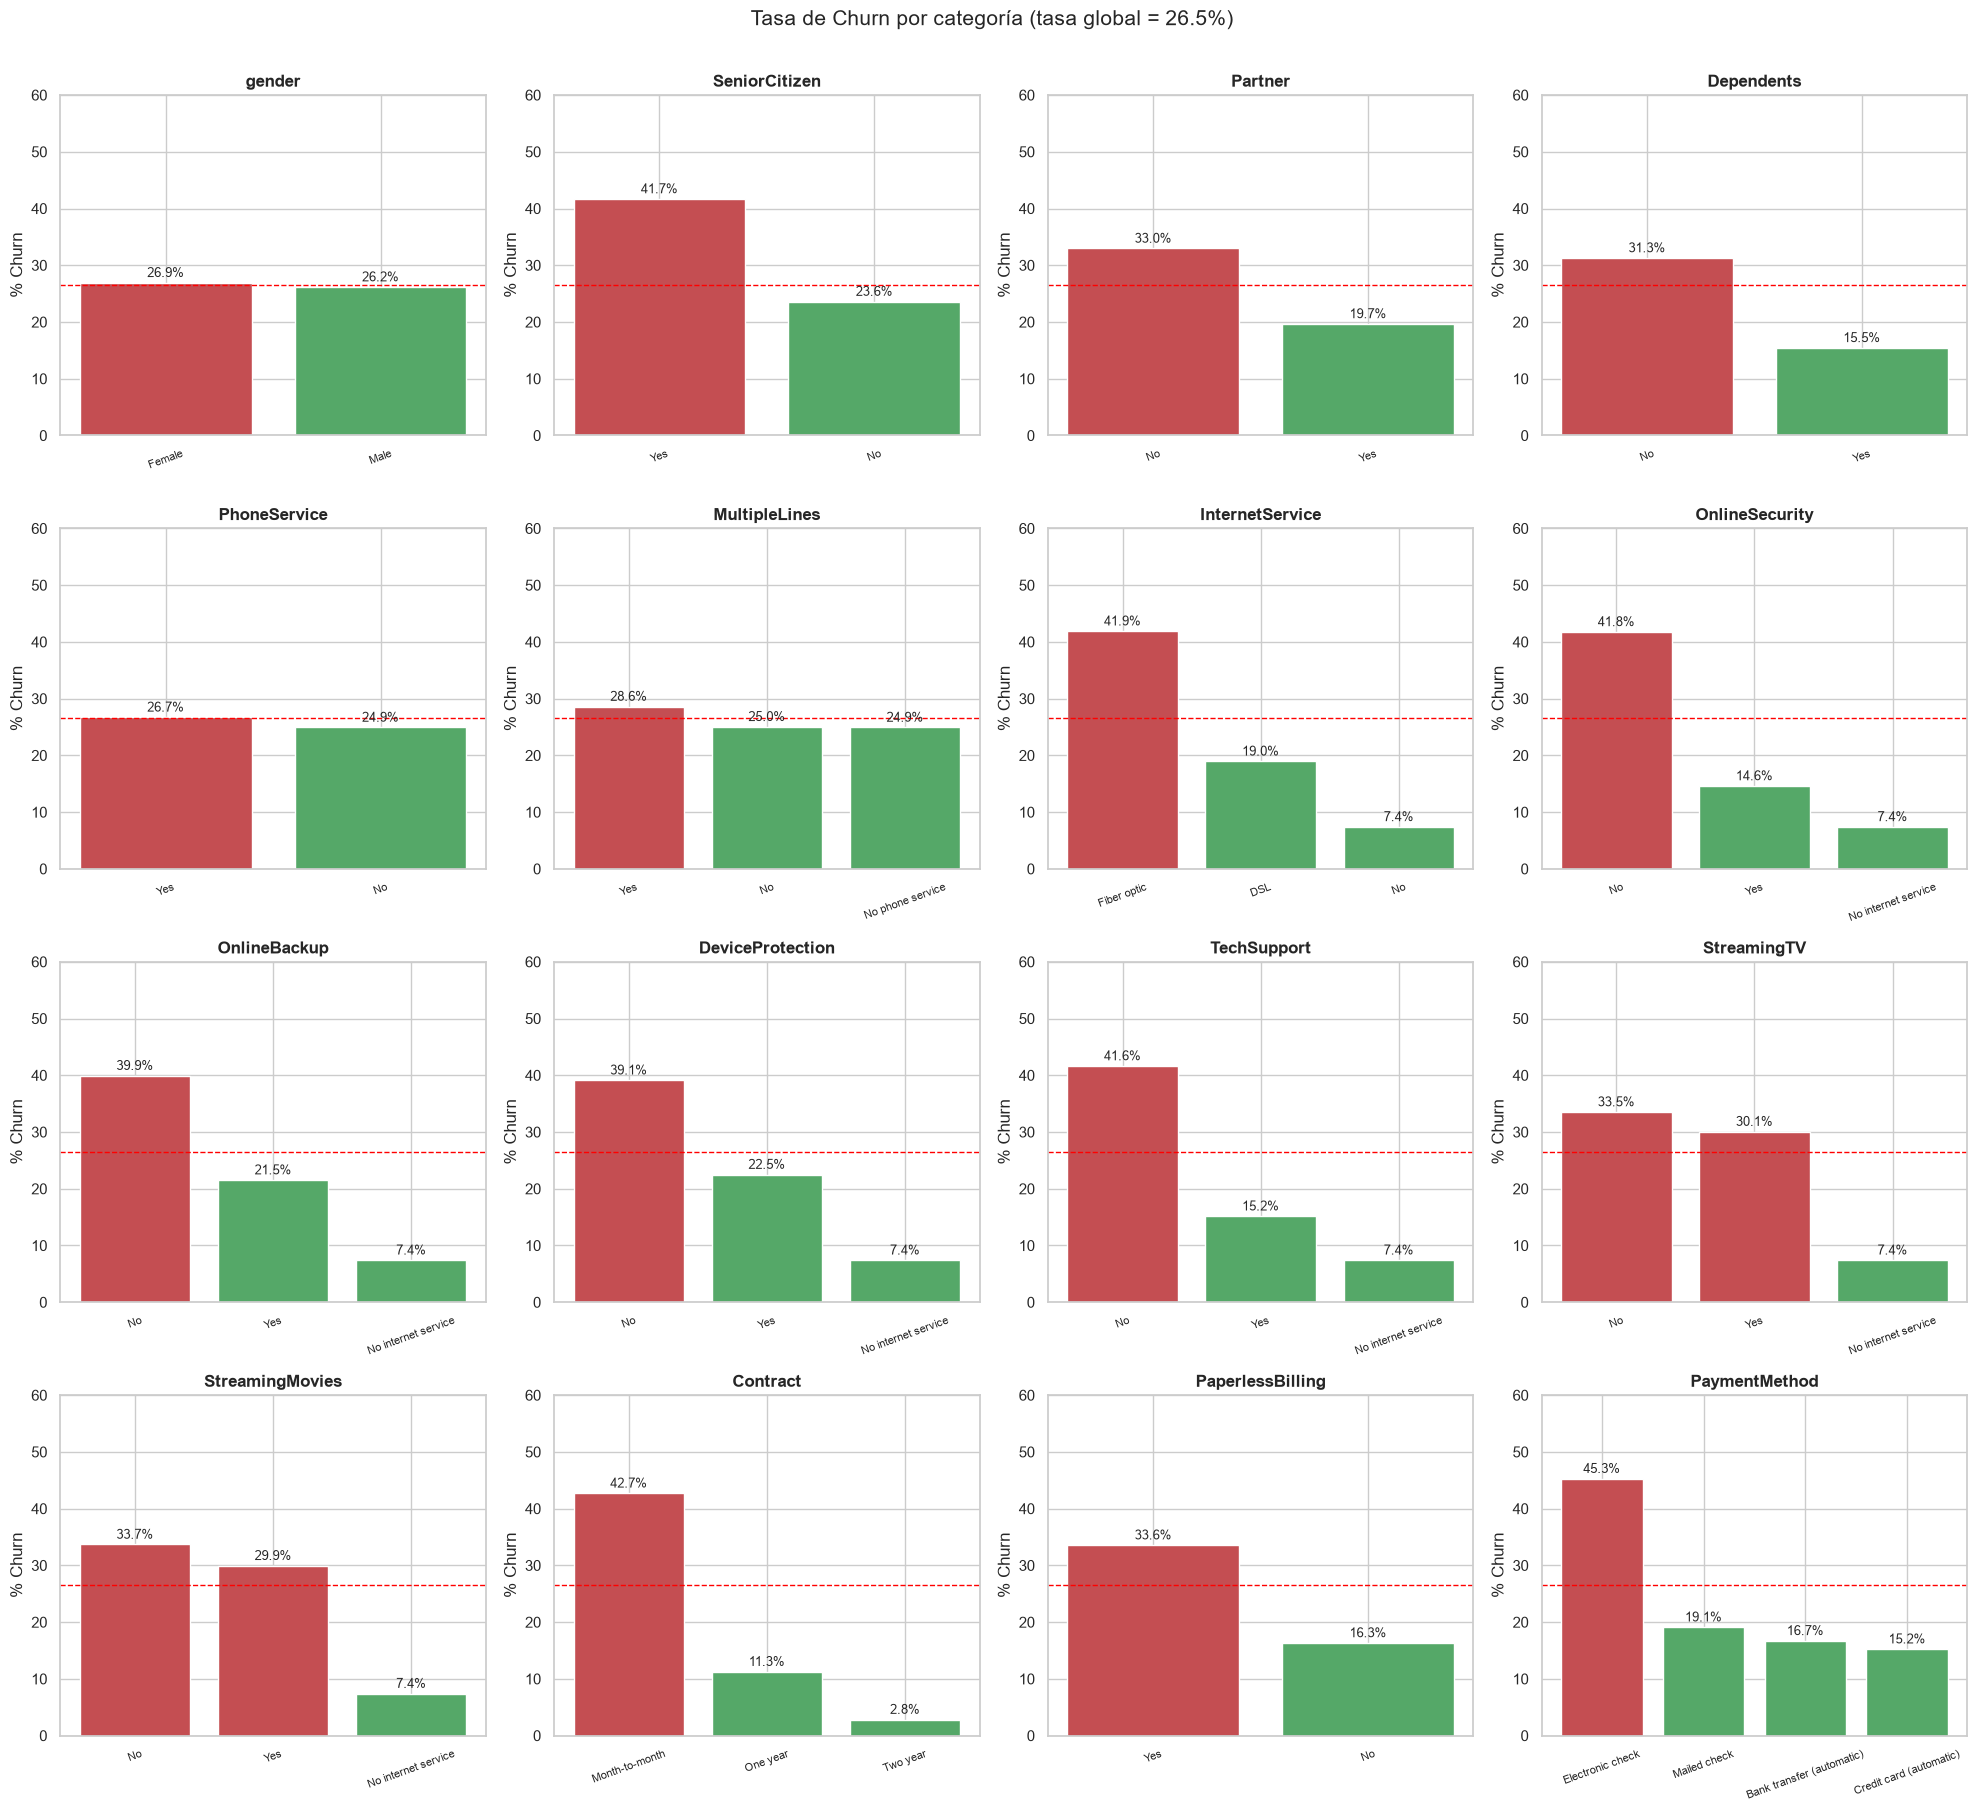

In [9]:
tasa_global = df_eda["Churn_bin"].mean() * 100
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for ax, col in zip(axes.ravel(), CAT_EDA):
    tasa = df_eda.groupby(col)["Churn_bin"].mean().sort_values(ascending=False) * 100
    barras = ax.bar(tasa.index.astype(str), tasa.values,
                    color=["#C44E52" if v > tasa_global else "#55A868" for v in tasa.values])
    ax.axhline(tasa_global, ls="--", color="red", lw=1)
    for b, v in zip(barras, tasa.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(col, fontsize=12, fontweight="bold")
    ax.set_ylabel("% Churn")
    ax.set_ylim(0, 60)
    ax.tick_params(axis="x", rotation=20, labelsize=8)
plt.suptitle(f"Tasa de Churn por categoría (tasa global = {tasa_global:.1f}%)", fontsize=15, y=1.005)
plt.tight_layout()
plt.show()

In [10]:
# Ranking: ¿qué variables separan mejor a quienes abandonan? (diferencia entre la categoría de mayor y menor churn)
filas = []
for col in CAT_EDA:
    tasa = df_eda.groupby(col)["Churn_bin"].mean() * 100
    filas.append({"Variable": col,
                  "Categoría más riesgosa": tasa.idxmax(), "% churn (máx)": round(tasa.max(), 1),
                  "Categoría menos riesgosa": tasa.idxmin(), "% churn (mín)": round(tasa.min(), 1),
                  "Diferencia (pp)": round(tasa.max() - tasa.min(), 1)})
pd.DataFrame(filas).sort_values("Diferencia (pp)", ascending=False).reset_index(drop=True)

,Variable,Categoría más riesgosa,% churn (máx),Categoría menos riesgosa,% churn (mín),Diferencia (pp)
0,Contract,Month-to-month,42.7,Two year,2.8,39.9
1,InternetService,Fiber optic,41.9,No,7.4,34.5
2,OnlineSecurity,No,41.8,No internet service,7.4,34.4
3,TechSupport,No,41.6,No internet service,7.4,34.2
4,OnlineBackup,No,39.9,No internet service,7.4,32.5
5,DeviceProtection,No,39.1,No internet service,7.4,31.7
6,PaymentMethod,Electronic check,45.3,Credit card (automatic),15.2,30.0
7,StreamingMovies,No,33.7,No internet service,7.4,26.3
8,StreamingTV,No,33.5,No internet service,7.4,26.1
9,SeniorCitizen,Yes,41.7,No,23.6,18.1


### 4.6 Permanencia (tenure) por tramos y correlaciones

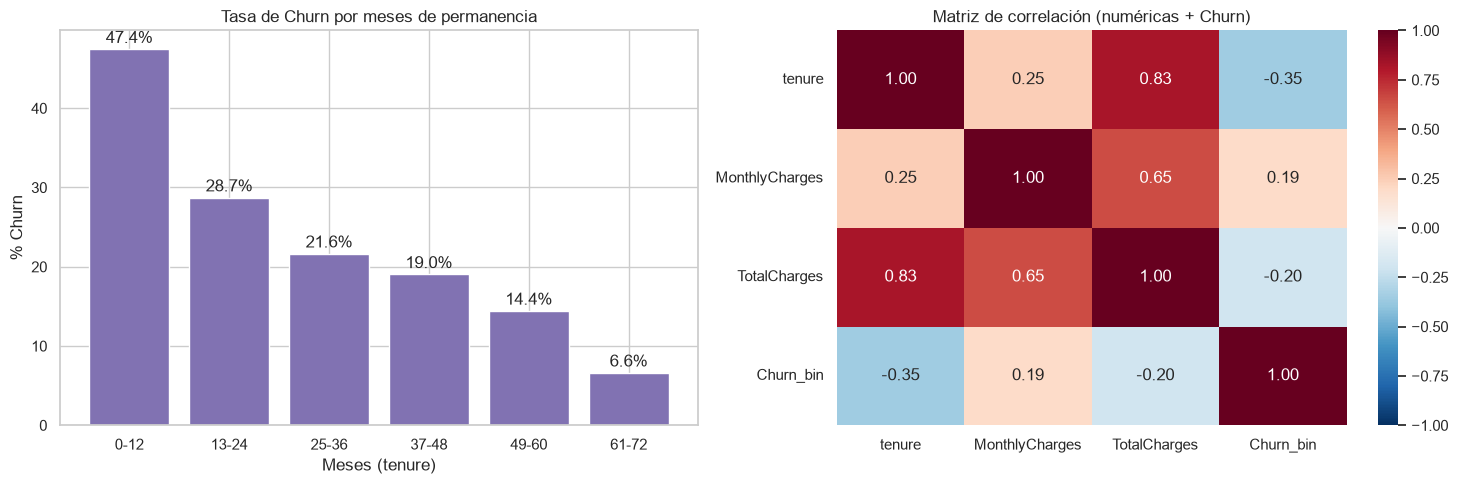

In [11]:
df_eda["tenure_grupo"] = pd.cut(df_eda["tenure"], bins=[-1, 12, 24, 36, 48, 60, 72],
                                labels=["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"])
tasa_tenure = df_eda.groupby("tenure_grupo", observed=True)["Churn_bin"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(tasa_tenure.index.astype(str), tasa_tenure.values, color="#8172B2")
for i, v in enumerate(tasa_tenure.values):
    axes[0].text(i, v + 0.8, f"{v:.1f}%", ha="center")
axes[0].set_title("Tasa de Churn por meses de permanencia")
axes[0].set_xlabel("Meses (tenure)")
axes[0].set_ylabel("% Churn")

corr = df_eda[NUM_EDA + ["Churn_bin"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title("Matriz de correlación (numéricas + Churn)")
plt.tight_layout()
plt.show()

### 4.7 Impacto económico del churn en este dataset

In [12]:
ingreso_mensual_total = df_eda["MonthlyCharges"].sum()
ingreso_mensual_perdido = df_eda.loc[df_eda["Churn"] == "Yes", "MonthlyCharges"].sum()
pct_clientes = df_eda["Churn_bin"].mean() * 100
pct_ingreso = ingreso_mensual_perdido / ingreso_mensual_total * 100

print(f"Facturación mensual total          : ${ingreso_mensual_total:,.2f}")
print(f"Facturación mensual perdida (churn): ${ingreso_mensual_perdido:,.2f}")
print(f"Equivale a una pérdida anual de    : ${ingreso_mensual_perdido * 12:,.2f}")
print(f"\nLos que abandonan son el {pct_clientes:.1f}% de los clientes, pero el {pct_ingreso:.1f}% de la facturación mensual.")
print(f"Cargo mensual promedio -> abandona: ${df_eda.loc[df_eda.Churn=='Yes','MonthlyCharges'].mean():.2f} | "
      f"continúa: ${df_eda.loc[df_eda.Churn=='No','MonthlyCharges'].mean():.2f}")

Facturación mensual total          : $456,116.60
Facturación mensual perdida (churn): $139,130.85
Equivale a una pérdida anual de    : $1,669,570.20

Los que abandonan son el 26.5% de los clientes, pero el 30.5% de la facturación mensual.
Cargo mensual promedio -> abandona: $74.44 | continúa: $61.27


### 4.8 Conclusiones del EDA
1. **Clases desbalanceadas:** 73,5 % *No* frente a 26,5 % *Yes*. Hay que balancear (SMOTE) y evaluar con métricas que miren la clase minoritaria.
2. **El tipo de contrato es el factor más fuerte:** los clientes *Month-to-month* abandonan un **42,7 %**, contra solo **2,8 %** con contrato de *Two year* (40 puntos de diferencia).
3. **El primer año es crítico:** clientes con 0–12 meses abandonan un **47,4 %**, y quienes llevan más de 5 años solo un **6,6 %**. La mediana de permanencia es **10 meses** en los que abandonan contra **38 meses** en los que se quedan. `tenure` es la numérica más correlacionada con churn (**−0,35**).
4. **Fibra óptica:** **41,9 %** de churn contra **7,4 %** en clientes sin internet. La fibra además es el servicio más caro (mediana de **$91,7** contra $56,2 en DSL), lo que sugiere un problema de precio/calidad.
5. **Servicios de protección y soporte:** sin `OnlineSecurity` el churn es **41,8 %** y sin `TechSupport` **41,6 %**. Los servicios de soporte "atan" al cliente.
6. **Método de pago:** *Electronic check* tiene **45,3 %** de churn contra **15,2 %** con tarjeta de crédito automática. El pago automático reduce la fricción y el abandono.
7. **Facturación:** los que abandonan pagan **más al mes** (mediana de $79,65 contra $64,43), pero acumulan menos `TotalCharges` porque se van pronto.
8. **Perfil demográfico:** los adultos mayores abandonan más (**41,7 %** contra 23,6 %), igual que los clientes sin pareja y sin dependientes.
9. **Variables casi irrelevantes:** `gender` (0,8 pp de diferencia) y `PhoneService` (1,8 pp).
10. **Multicolinealidad:** `TotalCharges ≈ tenure × MonthlyCharges`, y la correlación `tenure`–`TotalCharges` es **0,83**. No afecta mucho la predicción, pero sí la lectura de los coeficientes de la Regresión Logística.
11. **Impacto económico:** quienes abandonan son el 26,5 % de los clientes pero el **30,5 % de la facturación mensual**: **$139.131 al mes ≈ $1,67 millones al año**.

**Perfil típico de alto riesgo:** cliente nuevo, con contrato mes a mes, fibra óptica, sin soporte técnico ni seguridad en línea, que paga con cheque electrónico. Es justamente el cliente del ejemplo del enunciado.

## 5. Preprocesamiento
### 5.1 Limpieza de datos
Decisiones:
- **`TotalCharges`**: se convierte a número. Los 11 blancos corresponden a clientes con `tenure = 0`, así que se imputan con **0** (todavía no se les ha facturado). No se eliminan filas.
- **`customerID`**: se elimina porque es un identificador sin valor predictivo.
- **`SeniorCitizen`**: viene como 0/1; se pasa a `No`/`Yes` para tratarla igual que las demás variables binarias.
- **`Churn`** (objetivo): se codifica como `Yes = 1` (clase positiva) y `No = 0`.
- **Duplicados**: al quitar `customerID` aparecen algunas filas idénticas, pero son clientes **distintos** con el mismo perfil (por ejemplo, clientes nuevos con el plan más básico), así que se conservan.

In [13]:
df = df_raw.copy()

# TotalCharges: texto -> número; los blancos (tenure = 0) se imputan con 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
assert (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all()
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

df = df.drop(columns="customerID")
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Nulos después de limpiar:", int(df.isnull().sum().sum()))
print("Filas con perfil idéntico (se conservan):", df.duplicated().sum())
print("Shape final:", df.shape)

Nulos después de limpiar: 0
Filas con perfil idéntico (se conservan): 22
Shape final: (7043, 20)


### 5.2 Separación de variables predictoras (X) y objetivo (y)

In [14]:
NUM_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_COLS = [c for c in df.columns if c not in NUM_COLS + ["Churn"]]

X = df[NUM_COLS + CAT_COLS]
y = df["Churn"]
print(f"{len(NUM_COLS)} numéricas : {NUM_COLS}")
print(f"{len(CAT_COLS)} categóricas: {CAT_COLS}")

3 numéricas : ['tenure', 'MonthlyCharges', 'TotalCharges']
16 categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### 5.3 División entrenamiento / prueba (80 / 20, estratificada)
`stratify=y` mantiene la misma proporción de churn (~26,5 %) en ambos conjuntos. El conjunto de prueba **no se toca** hasta la evaluación final.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Entrenamiento: {X_train.shape[0]} filas | churn = {y_train.mean()*100:.2f}%")
print(f"Prueba       : {X_test.shape[0]} filas | churn = {y_test.mean()*100:.2f}%")

Entrenamiento: 5634 filas | churn = 26.54%
Prueba       : 1409 filas | churn = 26.54%


### 5.4 Codificación de categóricas y escalamiento de numéricas
Se usa un `ColumnTransformer`:
- **Numéricas → `StandardScaler`** (media 0, desviación 1). Es indispensable para KNN y SVM, que trabajan con distancias, y ayuda a la convergencia de Logistic Regression.
- **Categóricas → `OneHotEncoder`**: crea una columna binaria por categoría. Con `handle_unknown="ignore"`, una categoría nunca vista no rompe la predicción.

El transformador se ajusta **solo con entrenamiento** (dentro del pipeline) para evitar *data leakage*.

In [16]:
preprocesador = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
])

X_train_prep = preprocesador.fit_transform(X_train)
nombres_features = preprocesador.get_feature_names_out()
print("Variables originales:", X_train.shape[1], "-> variables después de codificar:", X_train_prep.shape[1])
pd.DataFrame(X_train_prep[:5], columns=nombres_features).round(2)

Variables originales: 19 -> variables después de codificar: 46


,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__SeniorCitizen_No,cat__SeniorCitizen_Yes,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,...,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
0,0.10,-0.52,-0.26,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,-0.71,0.34,-0.50,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.79,-0.81,-0.75,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3,-0.26,0.28,-0.17,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
4,-1.28,-0.68,-0.99,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


### 5.5 Balanceo de clases con SMOTE
**SMOTE** (*Synthetic Minority Over-sampling Technique*) crea ejemplos sintéticos de la clase minoritaria (`Churn = 1`) interpolando entre vecinos cercanos, hasta igualar las clases.

Reglas que se respetan:
- Se aplica **solo al conjunto de entrenamiento**. El de prueba conserva la distribución real (26,5 % churn); si no, las métricas serían optimistas.
- Se aplica **dentro de un pipeline** (`imblearn.Pipeline`), así que en la validación cruzada se balancea únicamente cada *fold* de entrenamiento.

         Antes de SMOTE  Después de SMOTE
No (0)             4139              4139
Yes (1)            1495              4139

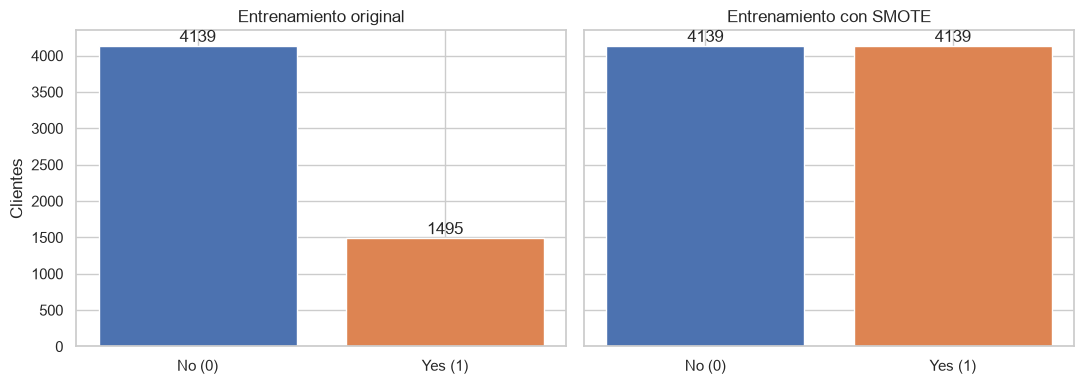

In [17]:
X_bal, y_bal = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_prep, y_train)

antes = y_train.value_counts().sort_index()
despues = pd.Series(y_bal).value_counts().sort_index()
print(pd.DataFrame({"Antes de SMOTE": antes, "Después de SMOTE": despues}, index=[0, 1])
      .rename(index={0: "No (0)", 1: "Yes (1)"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, datos, titulo in [(axes[0], antes, "Entrenamiento original"), (axes[1], despues, "Entrenamiento con SMOTE")]:
    ax.bar(["No (0)", "Yes (1)"], datos.values, color=colores)
    for i, v in enumerate(datos.values):
        ax.text(i, v + 50, str(v), ha="center")
    ax.set_title(titulo)
axes[0].set_ylabel("Clientes")
plt.tight_layout()
plt.show()

## 6. Entrenamiento y evaluación de modelos
Cada modelo se entrena dentro del mismo pipeline: **preprocesamiento → SMOTE → clasificador**. Así todos reciben exactamente los mismos datos y la comparación es justa.

| Modelo | Configuración |
|---|---|
| Logistic Regression | `max_iter=1000` |
| KNN | `n_neighbors=5` (distancia euclidiana) |
| SVM | kernel `rbf`, `probability=True` (para obtener probabilidades y ROC-AUC) |
| Decision Tree | parámetros por defecto (sin límite de profundidad) |
| Naive Bayes | `GaussianNB` |

In [18]:
modelos = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
}


def crear_pipeline(modelo):
    # preprocesamiento -> balanceo (solo en fit) -> clasificador
    return ImbPipeline([
        ("prep", clone(preprocesador)),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("modelo", clone(modelo)),
    ])


def calcular_metricas(y_real, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred),
        "Recall": recall_score(y_real, y_pred),
        "F1-Score": f1_score(y_real, y_pred),
        "ROC-AUC": roc_auc_score(y_real, y_proba),
    }

In [19]:
pipelines, resultados, resultados_train, probas, preds = {}, [], [], {}, {}

for nombre, modelo in modelos.items():
    pipe = crear_pipeline(modelo)
    pipe.fit(X_train, y_train)
    pipelines[nombre] = pipe

    # Prueba
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    preds[nombre], probas[nombre] = y_pred, y_proba
    resultados.append({"Modelo": nombre, **calcular_metricas(y_test, y_pred, y_proba)})

    # Entrenamiento (para medir overfitting)
    resultados_train.append({"Modelo": nombre, **calcular_metricas(
        y_train, pipe.predict(X_train), pipe.predict_proba(X_train)[:, 1])})

    print("=" * 62)
    print(f"  {nombre.upper()}")
    print("=" * 62)
    print(classification_report(y_test, y_pred, target_names=["No Churn (0)", "Churn (1)"], digits=4))
    print(f"ROC-AUC: {resultados[-1]['ROC-AUC']:.4f}\n")

  LOGISTIC REGRESSION
              precision    recall  f1-score   support

No Churn (0)     0.9069    0.7150    0.7996      1035
   Churn (1)     0.5025    0.7968    0.6163       374

    accuracy                         0.7367      1409
   macro avg     0.7047    0.7559    0.7080      1409
weighted avg     0.7995    0.7367    0.7509      1409

ROC-AUC: 0.8399



  KNN
              precision    recall  f1-score   support

No Churn (0)     0.8661    0.6937    0.7704      1035
   Churn (1)     0.4534    0.7032    0.5514       374

    accuracy                         0.6962      1409
   macro avg     0.6598    0.6985    0.6609      1409
weighted avg     0.7566    0.6962    0.7122      1409

ROC-AUC: 0.7685



  SVM
              precision    recall  f1-score   support

No Churn (0)     0.8835    0.7691    0.8223      1035
   Churn (1)     0.5295    0.7193    0.6100       374

    accuracy                         0.7559      1409
   macro avg     0.7065    0.7442    0.7161      1409
weighted avg     0.7895    0.7559    0.7660      1409

ROC-AUC: 0.8192



  DECISION TREE
              precision    recall  f1-score   support

No Churn (0)     0.8259    0.7836    0.8042      1035
   Churn (1)     0.4754    0.5428    0.5069       374

    accuracy                         0.7197      1409
   macro avg     0.6506    0.6632    0.6555      1409
weighted avg     0.7328    0.7197    0.7253      1409

ROC-AUC: 0.6630



  NAIVE BAYES
              precision    recall  f1-score   support

No Churn (0)     0.9096    0.6512    0.7590      1035
   Churn (1)     0.4596    0.8209    0.5893       374

    accuracy                         0.6962      1409
   macro avg     0.6846    0.7360    0.6741      1409
weighted avg     0.7901    0.6962    0.7139      1409

ROC-AUC: 0.8066



### 6.1 Tabla comparativa de métricas (conjunto de prueba)
En verde, el mejor valor de cada métrica.

> **Nota de reproducibilidad:** las salidas guardadas se generaron con el entorno de Colab (Python 3.13, scikit-learn 1.6.1, imbalanced-learn 0.14.2). Al re-ejecutar en otra versión o plataforma, algunas métricas de prueba pueden variar en el tercer decimal y los conteos de la matriz de confusión en ±1–3 clientes, por desempates en KNN y SMOTE. **Las conclusiones no cambian.** La validación cruzada, el ANOVA y Tukey son estables.

In [20]:
tabla = pd.DataFrame(resultados).set_index("Modelo")
tabla.style.format("{:.4f}").highlight_max(axis=0, color="#b6e3b6")

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Modelo,,,,,
Logistic Regression,0.7367,0.5025,0.7968,0.6163,0.8399
KNN,0.6962,0.4534,0.7032,0.5514,0.7685
SVM,0.7559,0.5295,0.7193,0.6100,0.8192
Decision Tree,0.7197,0.4754,0.5428,0.5069,0.6630
Naive Bayes,0.6962,0.4596,0.8209,0.5893,0.8066


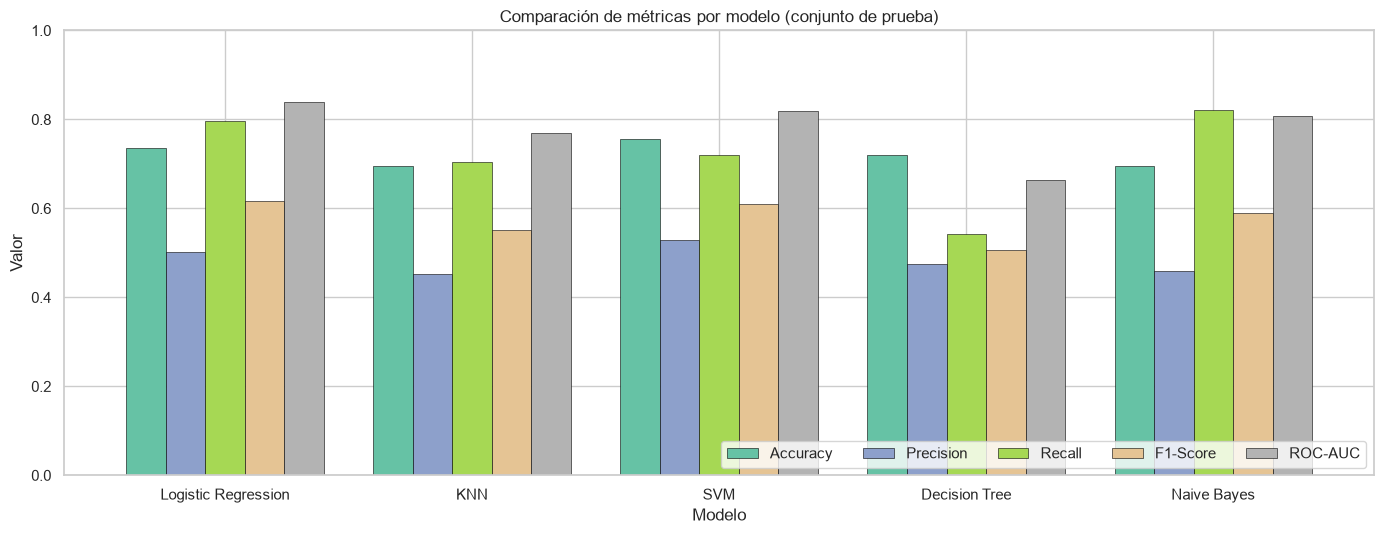

In [21]:
ax = tabla.plot(kind="bar", figsize=(14, 5.5), width=0.8, colormap="Set2", edgecolor="black", linewidth=0.4)
ax.set_title("Comparación de métricas por modelo (conjunto de prueba)")
ax.set_ylabel("Valor")
ax.set_ylim(0, 1)
ax.set_xticklabels(tabla.index, rotation=0)
ax.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.show()

### 6.2 Matrices de confusión
- **TN**: no abandona y el modelo dijo que no · **FP**: no abandona pero el modelo dijo que sí (falsa alarma)
- **FN**: abandona pero el modelo dijo que no (**cliente perdido sin aviso**) · **TP**: abandona y el modelo lo detectó

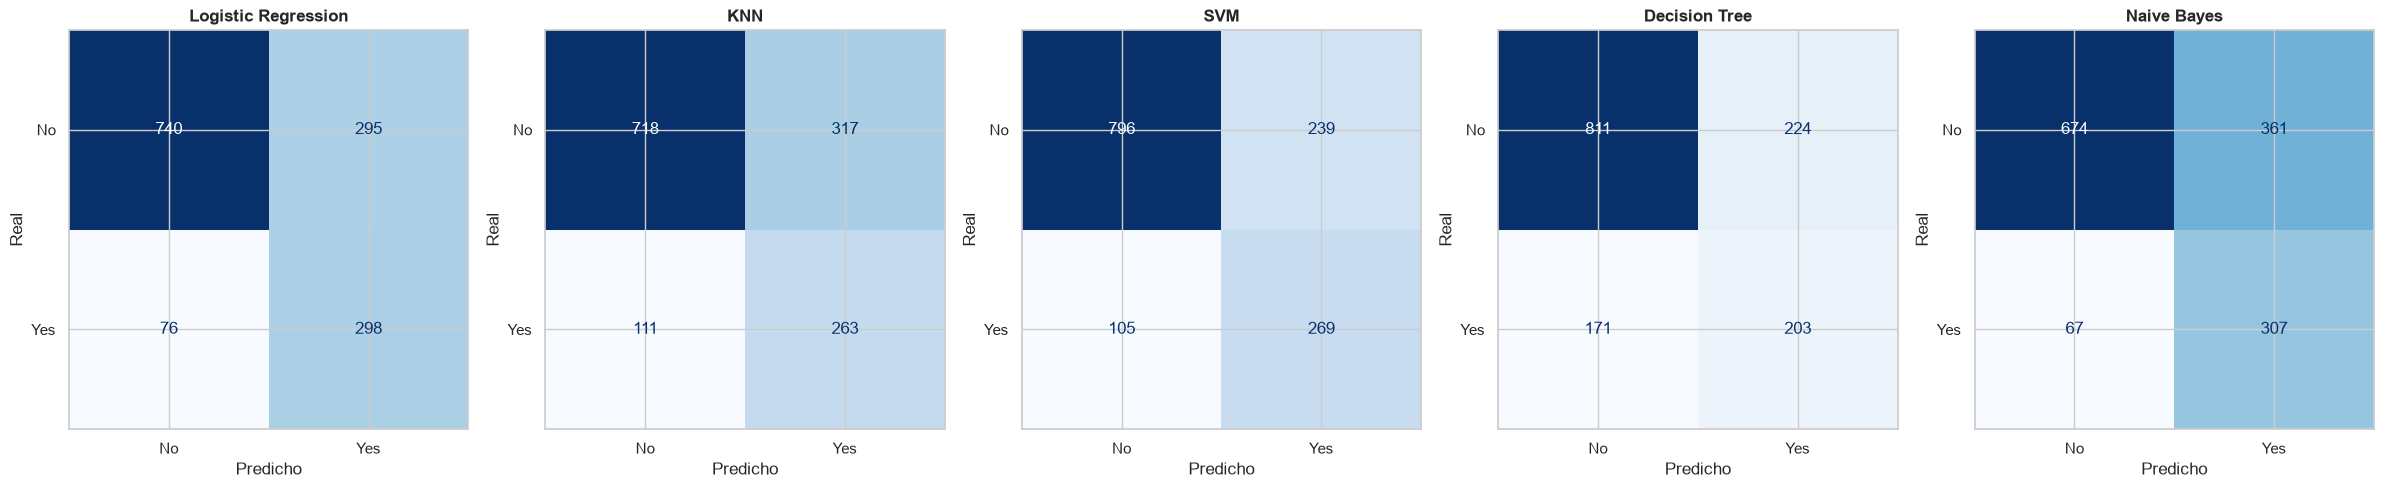

,TN,FP (falsa alarma),FN (churn no detectado),TP (churn detectado)
Modelo,,,,
Logistic Regression,740,295,76,298
KNN,718,317,111,263
SVM,796,239,105,269
Decision Tree,811,224,171,203
Naive Bayes,674,361,67,307


In [22]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.8))
for ax, (nombre, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["No", "Yes"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(nombre, fontweight="bold")
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

filas = []
for nombre, y_pred in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    filas.append({"Modelo": nombre, "TN": tn, "FP (falsa alarma)": fp, "FN (churn no detectado)": fn, "TP (churn detectado)": tp})
pd.DataFrame(filas).set_index("Modelo")

### 6.3 Curvas ROC

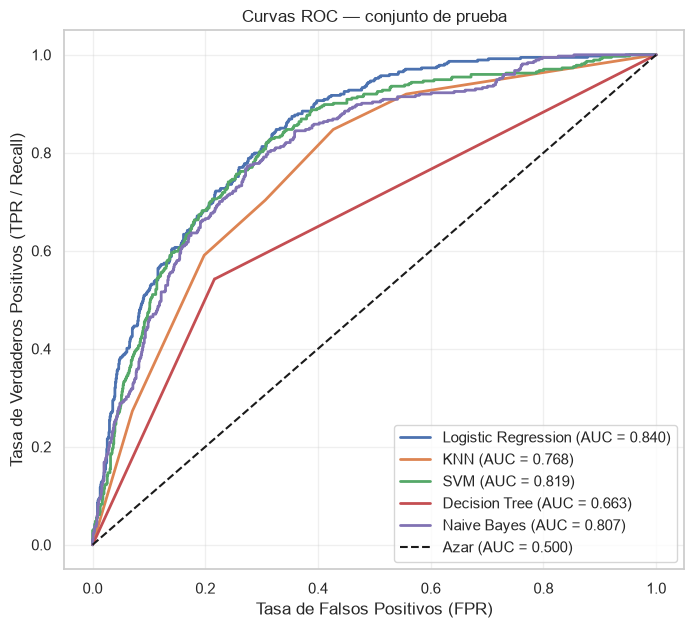

In [23]:
plt.figure(figsize=(8, 7))
for nombre, y_proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {roc_auc_score(y_test, y_proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.500)")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
plt.title("Curvas ROC — conjunto de prueba")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

### 6.4 Diagnóstico de overfitting (entrenamiento vs. prueba)
Si un modelo rinde mucho mejor en entrenamiento que en prueba, **memorizó** los datos en vez de aprender patrones generales.

In [24]:
tabla_train = pd.DataFrame(resultados_train).set_index("Modelo")
overfit = pd.DataFrame({
    "F1 train": tabla_train["F1-Score"], "F1 test": tabla["F1-Score"],
    "Brecha F1": tabla_train["F1-Score"] - tabla["F1-Score"],
    "AUC train": tabla_train["ROC-AUC"], "AUC test": tabla["ROC-AUC"],
    "Brecha AUC": tabla_train["ROC-AUC"] - tabla["ROC-AUC"],
})
arbol = pipelines["Decision Tree"].named_steps["modelo"]
print(f"Decision Tree sin podar -> profundidad: {arbol.get_depth()} | hojas: {arbol.get_n_leaves()}")
overfit.style.format("{:.4f}").background_gradient(subset=["Brecha F1", "Brecha AUC"], cmap="Reds")

Decision Tree sin podar -> profundidad: 31 | hojas: 1377


,F1 train,F1 test,Brecha F1,AUC train,AUC test,Brecha AUC
Modelo,,,,,,
Logistic Regression,0.6345,0.6163,0.0182,0.8489,0.8399,0.0090
KNN,0.7127,0.5514,0.1613,0.9356,0.7685,0.1672
SVM,0.6783,0.6100,0.0683,0.8805,0.8192,0.0614
Decision Tree,0.9963,0.5069,0.4894,1.0000,0.6630,0.3370
Naive Bayes,0.6009,0.5893,0.0116,0.8205,0.8066,0.0138


## 7. Fortalezas y debilidades de cada modelo (según los resultados)
Resultados en prueba (entre paréntesis, la media de la validación cruzada de 10 folds). Los valores marcados con ≈ pueden variar levemente al re-ejecutar (ver nota en 6.1).

#### Logistic Regression — F1 0,62 (0,632) · ROC-AUC 0,840 (0,846) · Recall 0,797
- ✅ **Mejor F1 y mejor ROC-AUC** tanto en prueba como en validación cruzada.
- ✅ Detecta **298 de 374** clientes que abandonan (solo 76 falsos negativos).
- ✅ **Casi no sobreajusta:** brecha train–test de 0,018 en F1 y 0,009 en AUC.
- ✅ Es rápida, liviana e **interpretable** (coeficientes / odds ratios), y sus probabilidades están bien calibradas para priorizar clientes.
- ❌ **Precision ≈ 0,50:** unas 295 falsas alarmas, es decir, 1 de cada 2 alertas es un cliente que no se iba.
- ❌ La frontera de decisión es lineal: no capta interacciones entre variables sin ingeniería de características.
- ❌ Es sensible a la multicolinealidad (`tenure`/`TotalCharges`), lo que complica leer algunos coeficientes por separado.

#### KNN — F1 0,55 (0,557) · ROC-AUC 0,77 (0,760) · Recall 0,70
- ✅ Es simple, no asume ninguna forma de los datos y capta relaciones no lineales locales.
- ❌ **Sobreajuste notable:** AUC de 0,94 en entrenamiento contra 0,77 en prueba (brecha ≈ 0,17). Con k = 5 memoriza vecinos, incluidos los puntos sintéticos de SMOTE.
- ❌ Tiene la **Precision más baja** (≈ 0,45) y unas 317 falsas alarmas.
- ❌ Con 46 dimensiones, casi todas binarias (one-hot), las distancias euclidianas pierden significado (*maldición de la dimensionalidad*).
- ❌ Es lento al predecir (calcula la distancia a todo el entrenamiento) y no es interpretable.

#### SVM (RBF) — F1 0,610 (0,621) · ROC-AUC 0,819 (0,825) · Recall 0,719
- ✅ Tiene el **mayor Accuracy (0,756)** y la **mayor Precision (0,530)**: es el que menos falsas alarmas genera (239).
- ✅ Segundo mejor F1, y en F1 **no tiene diferencia significativa con LR** (Tukey p = 0,66).
- ❌ Tiene menor Recall (0,719): **deja escapar 105 clientes** que abandonan, 29 más que LR.
- ❌ Es una caja negra: el kernel RBF no permite explicar por qué un cliente es riesgoso.
- ❌ Es el más costoso de entrenar (`probability=True` agrega una validación cruzada interna) y muestra un sobreajuste moderado (brecha de AUC de 0,061).

#### Decision Tree (sin podar) — F1 0,507 (0,511) · ROC-AUC 0,663 (0,667) · Recall 0,543
- ✅ No necesita escalamiento, capta relaciones no lineales y, si se poda, genera reglas si-entonces fáciles de explicar.
- ❌ **Peor modelo en F1, Recall y ROC-AUC.** No detecta **171 de 374** clientes que abandonan (46 %).
- ❌ **Sobreajuste extremo:** F1 de 0,996 y AUC de 1,000 en entrenamiento contra 0,507 y 0,663 en prueba. El árbol creció hasta **31 niveles y 1.377 hojas**: memorizó cada cliente.
- ❌ Sus hojas puras dan probabilidades de casi 0 o 1, por lo que ordena mal a los clientes (AUC bajo). Además es inestable ante pequeños cambios en los datos.

#### Naive Bayes (Gaussiano) — F1 0,59 (0,602) · ROC-AUC 0,807 (0,820) · Recall 0,821
- ✅ **Mayor Recall (0,821):** detecta 307 de 374 clientes que abandonan, con solo 67 falsos negativos.
- ✅ Casi no sobreajusta (brecha F1 de 0,012), es el más rápido de entrenar y funciona con pocos datos.
- ❌ **Más falsas alarmas (≈ 360)** y Precision baja (≈ 0,46): la campaña de retención se gastaría en muchos clientes que no se iban.
- ❌ Asume variables **independientes** y **normales**, algo que no se cumple aquí (los servicios de internet dependen entre sí, `tenure` y `TotalCharges` están correlacionadas, y las variables one-hot son binarias).
- ❌ Comparte con KNN el Accuracy más bajo (0,696).

## 8. Validación cruzada, ANOVA y prueba de hipótesis
Un solo split de prueba da **un único número por modelo**, y eso no permite saber si las diferencias son reales o fruto del azar de la partición. Para el ANOVA se necesitan **varias mediciones por modelo**, así que se usa **validación cruzada estratificada de 10 folds** sobre el conjunto de entrenamiento (SMOTE dentro de cada fold). Resultado: 10 valores de cada métrica por modelo.

> Para la SVM en la validación cruzada se usa `probability=False`: el ROC-AUC se calcula con `decision_function`, que da el mismo ordenamiento y evita 5 entrenamientos internos extra por fold.

In [25]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
METRICAS = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
            "F1-Score": "f1", "ROC-AUC": "roc_auc"}

scores_cv = {}
for nombre, modelo in modelos.items():
    if nombre == "SVM":
        modelo = clone(modelo).set_params(probability=False)
    r = cross_validate(crear_pipeline(modelo), X_train, y_train, cv=cv, scoring=METRICAS, n_jobs=-1)
    scores_cv[nombre] = {m: r[f"test_{m}"] for m in METRICAS}
    print(f"{nombre:<20} F1 = {scores_cv[nombre]['F1-Score'].mean():.4f} ± {scores_cv[nombre]['F1-Score'].std():.4f}"
          f" | ROC-AUC = {scores_cv[nombre]['ROC-AUC'].mean():.4f} ± {scores_cv[nombre]['ROC-AUC'].std():.4f}")

Logistic Regression  F1 = 0.6320 ± 0.0250 | ROC-AUC = 0.8460 ± 0.0151


KNN                  F1 = 0.5573 ± 0.0156 | ROC-AUC = 0.7599 ± 0.0098


SVM                  F1 = 0.6207 ± 0.0131 | ROC-AUC = 0.8252 ± 0.0115


Decision Tree        F1 = 0.5108 ± 0.0169 | ROC-AUC = 0.6666 ± 0.0119


Naive Bayes          F1 = 0.6017 ± 0.0154 | ROC-AUC = 0.8201 ± 0.0149


In [26]:
# Resumen: media ± desviación estándar de los 10 folds
resumen_cv = pd.DataFrame({n: {m: f"{v.mean():.4f} ± {v.std():.4f}" for m, v in s.items()}
                           for n, s in scores_cv.items()}).T
resumen_cv

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.7542 ± 0.0178,0.5247 ± 0.0233,0.7953 ± 0.0361,0.6320 ± 0.0250,0.8460 ± 0.0151
KNN,0.6913 ± 0.0121,0.4501 ± 0.0136,0.7325 ± 0.0290,0.5573 ± 0.0156,0.7599 ± 0.0098
SVM,0.7668 ± 0.0111,0.5467 ± 0.0176,0.7191 ± 0.0285,0.6207 ± 0.0131,0.8252 ± 0.0115
Decision Tree,0.7270 ± 0.0159,0.4885 ± 0.0283,0.5365 ± 0.0187,0.5108 ± 0.0169,0.6666 ± 0.0119
Naive Bayes,0.7043 ± 0.0177,0.4688 ± 0.0177,0.8408 ± 0.0250,0.6017 ± 0.0154,0.8201 ± 0.0149


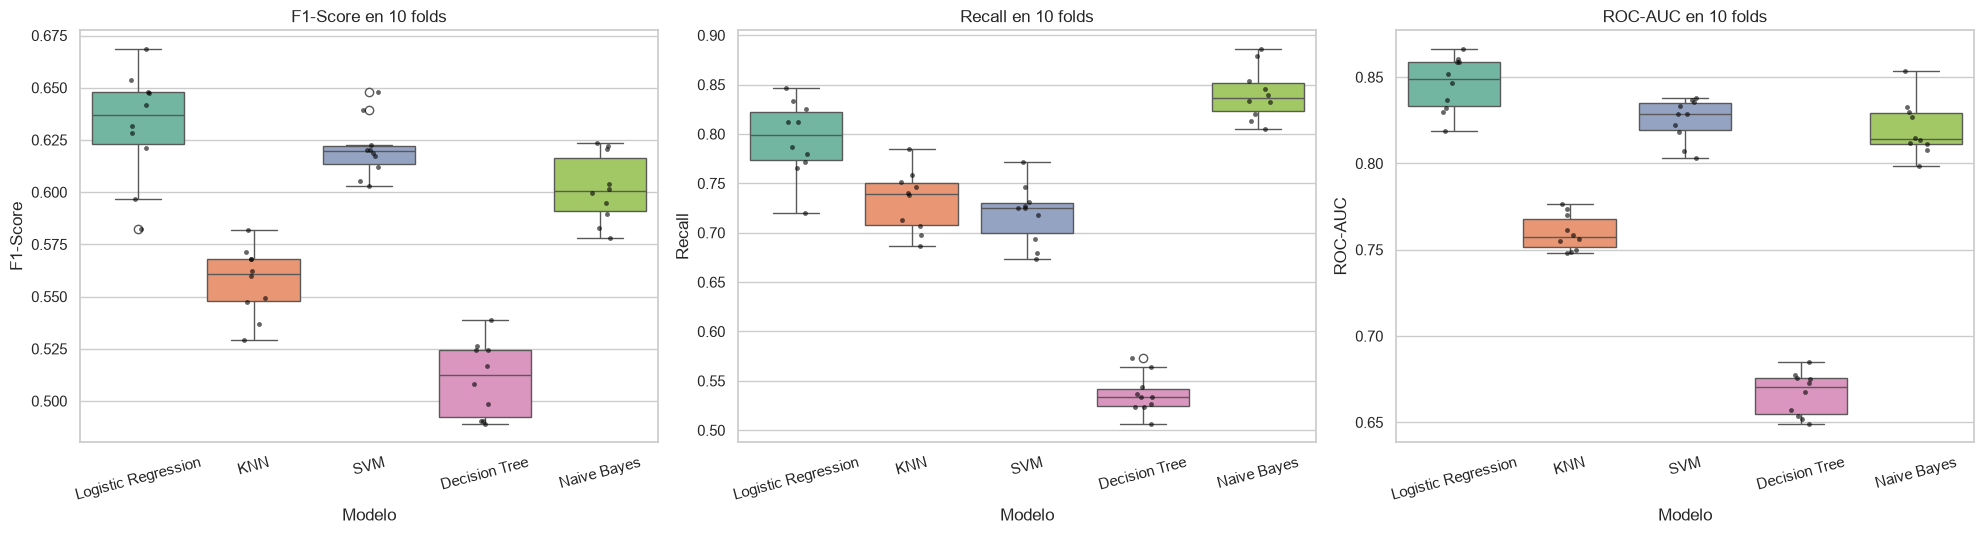

In [27]:
# Formato largo: una fila por (modelo, fold)
cv_largo = pd.DataFrame([{"Modelo": n, "Fold": i + 1, **{m: s[m][i] for m in METRICAS}}
                         for n, s in scores_cv.items() for i in range(10)])

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, m in zip(axes, ["F1-Score", "Recall", "ROC-AUC"]):
    sns.boxplot(data=cv_largo, x="Modelo", y=m, ax=ax, palette="Set2")
    sns.stripplot(data=cv_largo, x="Modelo", y=m, ax=ax, color="black", size=3.5, alpha=0.6)
    ax.set_title(f"{m} en 10 folds")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### 8.1 Supuestos del ANOVA
El ANOVA de un factor supone **normalidad** dentro de cada grupo (Shapiro-Wilk) y **homogeneidad de varianzas** (Levene). Con n = 10 por grupo el ANOVA es razonablemente robusto a desviaciones leves de normalidad. Si Levene se rechaza, conviene apoyarse además en la prueba de Tukey y en la diferencia de medias.

In [28]:
filas = []
for m in METRICAS:
    grupos = [scores_cv[n][m] for n in modelos]
    p_shapiro = [shapiro(g).pvalue for g in grupos]
    filas.append({"Métrica": m,
                  "Shapiro: grupos normales (p>0.05)": f"{sum(p > 0.05 for p in p_shapiro)}/5",
                  "Levene p-value": round(levene(*grupos).pvalue, 4)})
pd.DataFrame(filas).set_index("Métrica")

,Shapiro: grupos normales (p>0.05),Levene p-value
Métrica,,
Accuracy,5/5,0.4848
Precision,5/5,0.2277
Recall,5/5,0.3559
F1-Score,5/5,0.3116
ROC-AUC,5/5,0.7055


### 8.2 ANOVA de un factor — Hipótesis

**Hipótesis: existe un mejor modelo basado en diferencias significativas entre métricas**
- **H₀:** No hay diferencias significativas entre los modelos (μ_LR = μ_KNN = μ_SVM = μ_DT = μ_NB)
- **H₁:** Sí hay diferencias significativas entre los modelos (al menos una media es distinta)

Nivel de significancia: **α = 0.05**. Si *p-value < α*, se rechaza H₀.

In [29]:
alpha = 0.05
filas = []
for m in METRICAS:
    F, p = f_oneway(*[scores_cv[n][m] for n in modelos])
    filas.append({"Métrica": m, "F-statistic": round(F, 4), "p-value": p,
                  "Decisión": "Se rechaza H0" if p < alpha else "No se rechaza H0"})
anova = pd.DataFrame(filas).set_index("Métrica")
anova.style.format({"p-value": "{:.2e}", "F-statistic": "{:.4f}"})

,F-statistic,p-value,Decisión
Métrica,,,
Accuracy,39.9495,2.89e-14,Se rechaza H0
Precision,32.9739,7.47e-13,Se rechaza H0
Recall,154.5779,1.12e-25,Se rechaza H0
F1-Score,72.1971,5.37e-19,Se rechaza H0
ROC-AUC,289.3981,1.78e-31,Se rechaza H0


In [30]:
# Detalle para la métrica principal: F1-Score (equilibrio entre Precision y Recall)
METRICA_PRINCIPAL = "F1-Score"
F, p = f_oneway(*[scores_cv[n][METRICA_PRINCIPAL] for n in modelos])

print("===== RESULTADOS ANOVA (F1-Score) =====")
print("F-statistic:", round(F, 4))
print("p-value    :", f"{p:.2e}")

medias = {n: scores_cv[n][METRICA_PRINCIPAL].mean() for n in modelos}
print("\n===== PROMEDIO DE F1-SCORE (10 folds) =====")
for n, v in sorted(medias.items(), key=lambda kv: -kv[1]):
    print(f"{n:<20}: {v:.4f}")

print("\n===== INTERPRETACIÓN =====")
if p < alpha:
    print(f"p-value ({p:.2e}) < alpha ({alpha}) -> SE RECHAZA H0.")
    print("Existen diferencias estadísticamente significativas entre los modelos.")
else:
    print(f"p-value ({p:.2e}) >= alpha ({alpha}) -> NO se rechaza H0.")
    print("No existen diferencias significativas entre los modelos.")

===== RESULTADOS ANOVA (F1-Score) =====
F-statistic: 72.1971
p-value    : 5.37e-19

===== PROMEDIO DE F1-SCORE (10 folds) =====
Logistic Regression : 0.6320
SVM                 : 0.6207
Naive Bayes         : 0.6017
KNN                 : 0.5573
Decision Tree       : 0.5108

===== INTERPRETACIÓN =====
p-value (5.37e-19) < alpha (0.05) -> SE RECHAZA H0.
Existen diferencias estadísticamente significativas entre los modelos.


### 8.3 Prueba post-hoc de Tukey HSD
El ANOVA solo dice que **al menos un** modelo es diferente, pero no **cuál**. La prueba de Tukey compara todos los pares de modelos controlando el error por comparaciones múltiples. `reject = True` significa que ese par sí difiere significativamente.

In [31]:
for m in ["F1-Score", "ROC-AUC", "Recall"]:
    tukey = pairwise_tukeyhsd(endog=cv_largo[m], groups=cv_largo["Modelo"], alpha=alpha)
    print(f"\n===== TUKEY HSD — {m} =====")
    print(tukey.summary())


===== TUKEY HSD — F1-Score =====
             Multiple Comparison of Means - Tukey HSD, FWER=0.05              
       group1              group2       meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------------
      Decision Tree                 KNN   0.0466    0.0  0.0229  0.0703   True
      Decision Tree Logistic Regression   0.1212    0.0  0.0975  0.1449   True
      Decision Tree         Naive Bayes   0.0909    0.0  0.0672  0.1146   True
      Decision Tree                 SVM   0.1099    0.0  0.0862  0.1336   True
                KNN Logistic Regression   0.0746    0.0  0.0509  0.0983   True
                KNN         Naive Bayes   0.0443    0.0  0.0206   0.068   True
                KNN                 SVM   0.0633    0.0  0.0396   0.087   True
Logistic Regression         Naive Bayes  -0.0303 0.0061  -0.054 -0.0066   True
Logistic Regression                 SVM  -0.0113 0.6582  -0.035  0.0124  False
        Naive Baye


===== TUKEY HSD — ROC-AUC =====
             Multiple Comparison of Means - Tukey HSD, FWER=0.05              
       group1              group2       meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------------
      Decision Tree                 KNN   0.0933    0.0  0.0761  0.1105   True
      Decision Tree Logistic Regression   0.1794    0.0  0.1622  0.1966   True
      Decision Tree         Naive Bayes   0.1535    0.0  0.1363  0.1707   True
      Decision Tree                 SVM   0.1586    0.0  0.1414  0.1758   True
                KNN Logistic Regression   0.0861    0.0  0.0689  0.1033   True
                KNN         Naive Bayes   0.0602    0.0   0.043  0.0774   True
                KNN                 SVM   0.0653    0.0  0.0481  0.0825   True
Logistic Regression         Naive Bayes  -0.0259 0.0009 -0.0431 -0.0087   True
Logistic Regression                 SVM  -0.0208 0.0108  -0.038 -0.0036   True
        Naive Bayes


===== TUKEY HSD — Recall =====
             Multiple Comparison of Means - Tukey HSD, FWER=0.05              
       group1              group2       meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------------
      Decision Tree                 KNN    0.196    0.0  0.1585  0.2336   True
      Decision Tree Logistic Regression   0.2589    0.0  0.2213  0.2964   True
      Decision Tree         Naive Bayes   0.3044    0.0  0.2668  0.3419   True
      Decision Tree                 SVM   0.1827    0.0  0.1451  0.2202   True
                KNN Logistic Regression   0.0628 0.0002  0.0253  0.1004   True
                KNN         Naive Bayes   0.1083    0.0  0.0708  0.1459   True
                KNN                 SVM  -0.0134 0.8486 -0.0509  0.0242  False
Logistic Regression         Naive Bayes   0.0455 0.0105   0.008  0.0831   True
Logistic Regression                 SVM  -0.0762    0.0 -0.1138 -0.0387   True
        Naive Bayes 

### 8.4 Conclusión de la prueba de hipótesis
**1. ANOVA:** en las **5 métricas** el *p-value* es mucho menor que α = 0,05:

| Métrica | F | p-value | Decisión |
|---|---|---|---|
| Accuracy | 39,95 | 2,89·10⁻¹⁴ | Se rechaza H₀ |
| Precision | 32,97 | 7,47·10⁻¹³ | Se rechaza H₀ |
| Recall | 154,58 | 1,12·10⁻²⁵ | Se rechaza H₀ |
| **F1-Score** | **72,20** | **5,37·10⁻¹⁹** | **Se rechaza H₀** |
| **ROC-AUC** | **289,40** | **1,78·10⁻³¹** | **Se rechaza H₀** |

➡️ **Se rechaza H₀ y se acepta H₁: sí hay diferencias significativas entre los modelos.**

**2. Supuestos:** Shapiro-Wilk no rechaza la normalidad en los 5 modelos para ninguna métrica, y Levene no rechaza la homogeneidad de varianzas (todos los p > 0,05). El ANOVA es válido.

**3. Tukey HSD (¿cuál es el mejor?):**
- **F1-Score:** Logistic Regression es significativamente mejor que KNN, Decision Tree y Naive Bayes (contra NB: p = 0,006). Contra **SVM la diferencia no es significativa** (p = 0,66): en F1 hay un empate estadístico.
- **ROC-AUC:** Logistic Regression es significativamente mejor que **los otros 4 modelos, incluida SVM** (+0,021, p = 0,011).
- **Recall:** Logistic Regression supera significativamente a SVM (+0,076), KNN y Decision Tree. Naive Bayes la supera en Recall (+0,045), pero a costa de una Precision mucho menor.

**Conclusión:** **sí existe un mejor modelo, y es la Regresión Logística.** Es el único modelo que no es superado significativamente por ningún otro en F1 ni en ROC-AUC, y desempata con SVM porque es significativamente mejor en ROC-AUC y en Recall.

> Nota metodológica: los 5 modelos se evaluaron sobre los mismos 10 folds. Se aplicó ANOVA de un factor, como pide el enunciado. Con *p-values* tan bajos (≤ 10⁻¹²), la conclusión no cambia con pruebas para medidas repetidas (Friedman).

## 9. Selección del mejor modelo
Criterios del enunciado: **balance entre métricas**, **capacidad predictiva** e **interpretabilidad empresarial**.

In [32]:
medias_cv = pd.DataFrame({n: {m: v.mean() for m, v in s.items()} for n, s in scores_cv.items()}).T
ranking = medias_cv.rank(ascending=False).astype(int)
ranking.columns = [f"Rank {c}" for c in ranking.columns]
ranking["Rank promedio"] = ranking.mean(axis=1).round(2)

interpretabilidad = {"Logistic Regression": "Alta (coeficientes / odds ratios)", "Decision Tree": "Alta (reglas si-entonces)",
                     "Naive Bayes": "Media (probabilidades condicionales)", "KNN": "Baja (sin modelo explícito)",
                     "SVM": "Baja (kernel RBF, caja negra)"}
seleccion = medias_cv.round(4).join(ranking["Rank promedio"])
seleccion["Interpretabilidad"] = pd.Series(interpretabilidad)
seleccion.sort_values("Rank promedio")

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Rank promedio,Interpretabilidad
Logistic Regression,0.7542,0.5247,0.7953,0.6320,0.8460,1.6,Alta (coeficientes / odds ratios)
SVM,0.7668,0.5467,0.7191,0.6207,0.8252,2.0,"Baja (kernel RBF, caja negra)"
Naive Bayes,0.7043,0.4688,0.8408,0.6017,0.8201,3.0,Media (probabilidades condicionales)
KNN,0.6913,0.4501,0.7325,0.5573,0.7599,4.2,Baja (sin modelo explícito)
Decision Tree,0.7270,0.4885,0.5365,0.5108,0.6666,4.2,Alta (reglas si-entonces)


In [33]:
MEJOR = "Logistic Regression"
print(f"Modelo seleccionado: {MEJOR}")
print("\nMétricas en el conjunto de prueba:")
print(tabla.loc[MEJOR].round(4).to_string())

Modelo seleccionado: Logistic Regression

Métricas en el conjunto de prueba:
Accuracy     0.7367
Precision    0.5025
Recall       0.7968
F1-Score     0.6163
ROC-AUC      0.8399


### 9.1 Justificación técnica
**Modelo seleccionado: Logistic Regression**

| Criterio | Evidencia |
|---|---|
| **Balance entre métricas** | Mejor F1 en CV (0,632) y en prueba (≈ 0,62). Recall alto (0,797) sin hundir la Precision como Naive Bayes. Mejor *rank* promedio (1,6). |
| **Capacidad predictiva** | Mejor ROC-AUC en CV (0,846) y en prueba (0,840). Tukey confirma que es **significativamente superior** en AUC a los otros 4 modelos. |
| **Generalización** | Brecha train–test mínima (F1 0,018 · AUC 0,009) y poca variación entre folds: no hay overfitting. |
| **Interpretabilidad empresarial** | Cada coeficiente se traduce en un *odds ratio* explicable a marketing, por ejemplo: "tener contrato mes a mes multiplica por ~2 las odds de abandonar". |
| **Operación** | Entrena y predice en milisegundos, pesa poco y entrega probabilidades confiables para ordenar clientes por riesgo. |

**¿Por qué no SVM?** Empata en F1, pero es significativamente peor en ROC-AUC y Recall: deja escapar 105 clientes que abandonan, contra 76 de LR. Además es una caja negra.
**¿Por qué no Naive Bayes?** Tiene más Recall, pero genera unas 360 falsas alarmas y su F1 y su AUC son significativamente menores.

### 9.2 Interpretabilidad: ¿qué factores impulsan el churn?
En la Regresión Logística cada coeficiente indica cómo cambia el *log-odds* de abandonar. El **odds ratio** (`e^coef`) se lee así: > 1 aumenta el riesgo de churn y < 1 lo reduce.

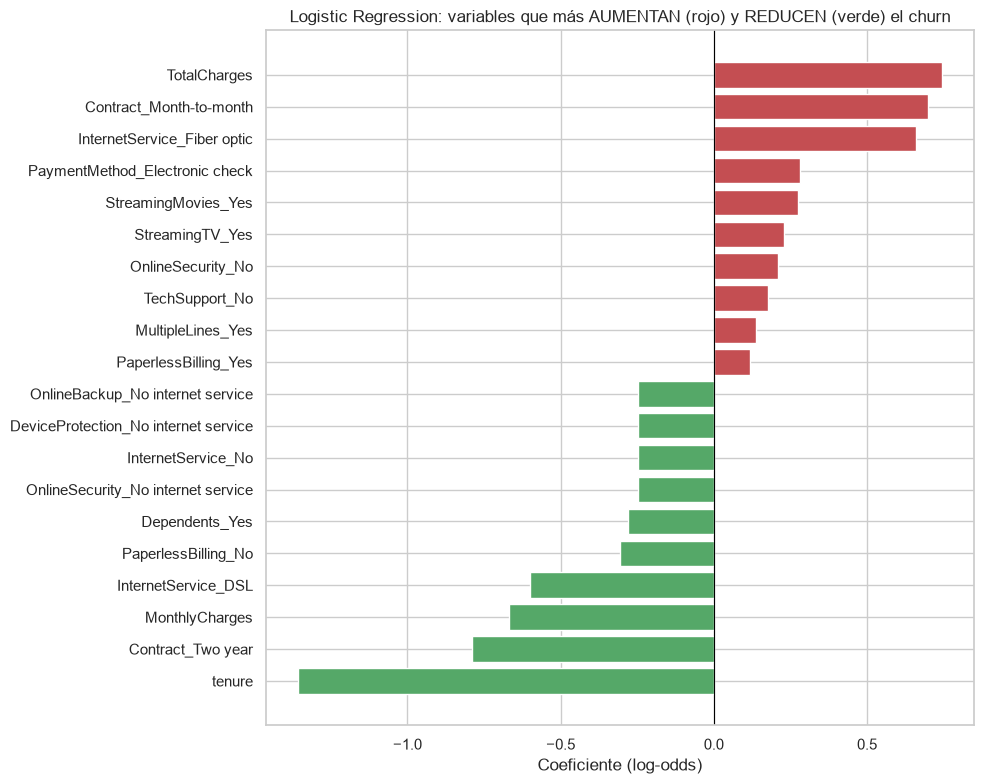

,Variable,Coeficiente,Odds ratio
0,TotalCharges,0.744,2.105
1,Contract_Month-to-month,0.700,2.013
2,InternetService_Fiber optic,0.659,1.933
3,PaymentMethod_Electronic check,0.282,1.326
4,StreamingMovies_Yes,0.274,1.315
5,StreamingTV_Yes,0.228,1.257
6,OnlineSecurity_No,0.210,1.234
7,TechSupport_No,0.176,1.192
8,MultipleLines_Yes,0.139,1.149
9,PaperlessBilling_Yes,0.117,1.124


In [34]:
lr = pipelines["Logistic Regression"].named_steps["modelo"]
coefs = pd.DataFrame({"Variable": nombres_features, "Coeficiente": lr.coef_[0]})
coefs["Odds ratio"] = np.exp(coefs["Coeficiente"])
coefs["Variable"] = coefs["Variable"].str.replace("num__", "").str.replace("cat__", "")
top = pd.concat([coefs.nlargest(10, "Coeficiente"), coefs.nsmallest(10, "Coeficiente")]).sort_values("Coeficiente")

plt.figure(figsize=(10, 8))
plt.barh(top["Variable"], top["Coeficiente"], color=["#C44E52" if c > 0 else "#55A868" for c in top["Coeficiente"]])
plt.axvline(0, color="black", lw=0.8)
plt.title("Logistic Regression: variables que más AUMENTAN (rojo) y REDUCEN (verde) el churn")
plt.xlabel("Coeficiente (log-odds)")
plt.tight_layout()
plt.show()

coefs.sort_values("Coeficiente", ascending=False).head(10).round(3).reset_index(drop=True)

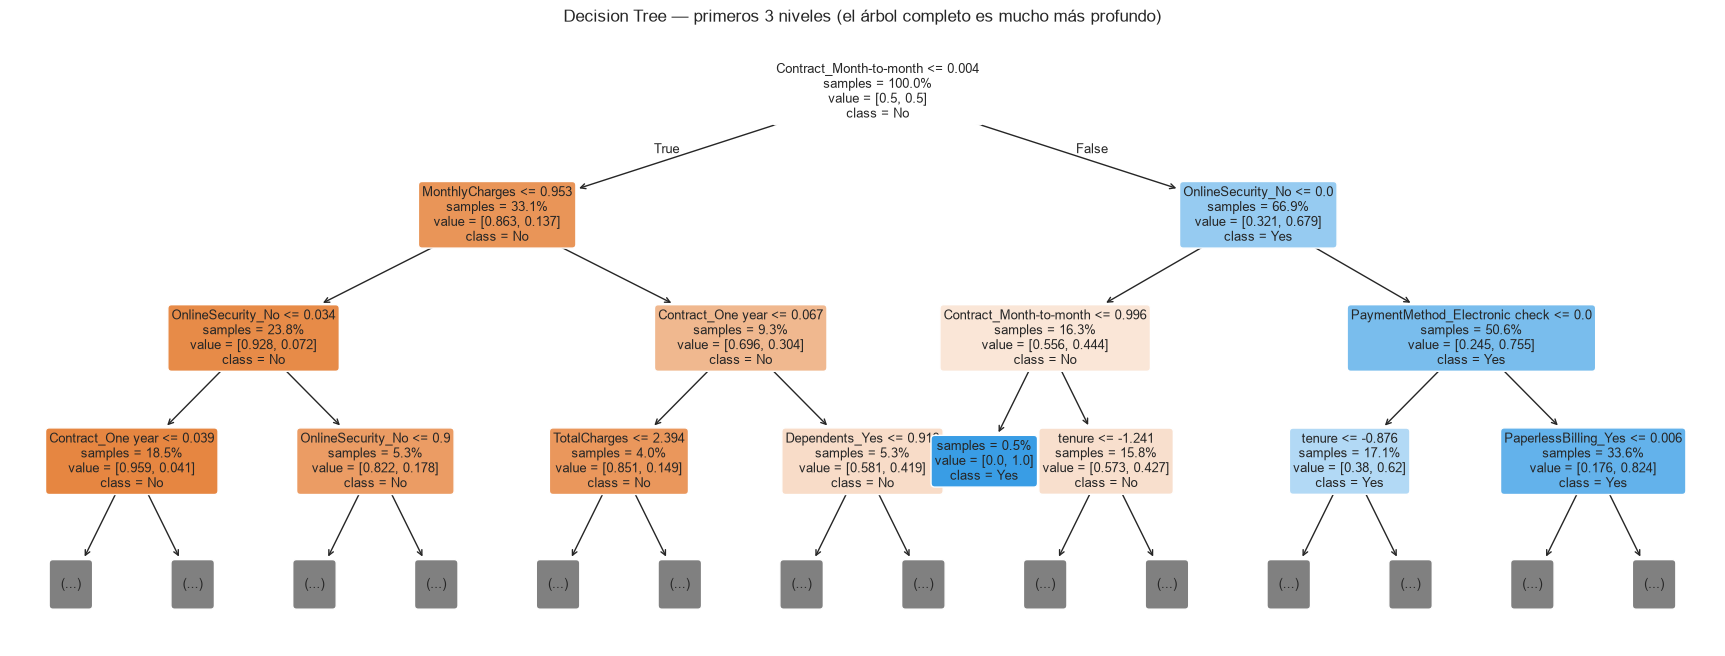

In [35]:
# Para comparar interpretabilidad: primeros niveles del Decision Tree
plt.figure(figsize=(22, 8))
plot_tree(pipelines["Decision Tree"].named_steps["modelo"], max_depth=3, feature_names=[
          f.replace("num__", "").replace("cat__", "") for f in nombres_features],
          class_names=["No", "Yes"], filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Decision Tree — primeros 3 niveles (el árbol completo es mucho más profundo)")
plt.show()

### 9.3 Guardar el modelo final
Se guarda un pipeline de `scikit-learn` (**preprocesamiento + clasificador**) listo para recibir datos crudos. SMOTE no se incluye porque solo actúa durante el entrenamiento. También se guardan metadatos (valores por defecto y opciones de cada variable) para el sistema de predicción y la app web.

In [36]:
mejor_pipe = pipelines[MEJOR]
modelo_final = SkPipeline([("prep", mejor_pipe.named_steps["prep"]),
                           ("modelo", mejor_pipe.named_steps["modelo"])])

# Valores por defecto para las variables que el usuario no ingrese
valores_defecto = {c: X_train[c].mode()[0] for c in CAT_COLS}
valores_defecto.update({c: float(X_train[c].median()) for c in NUM_COLS})

metadata = {
    "modelo": MEJOR,
    "umbral": 0.5,
    "num_cols": NUM_COLS,
    "cat_cols": CAT_COLS,
    "defaults": valores_defecto,
    "opciones": {c: sorted(X_train[c].unique().tolist()) for c in CAT_COLS},
    "rangos": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in NUM_COLS},
    "metricas_test": {k: round(float(v), 4) for k, v in tabla.loc[MEJOR].items()},
}

joblib.dump(modelo_final, "modelo_churn.pkl")
with open("metadata_churn.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print("Guardados: modelo_churn.pkl y metadata_churn.json")

Guardados: modelo_churn.pkl y metadata_churn.json


## 10. Sistema de predicción de nuevos clientes
El usuario ingresa manualmente los datos de un cliente. Las variables que no ingresa toman el valor más frecuente del entrenamiento, y `TotalCharges`, si no se da, se estima como `tenure × MonthlyCharges`. Además, se corrigen combinaciones imposibles: por ejemplo, si `InternetService = No`, los servicios de internet pasan a `No internet service`. El sistema devuelve:
- **Probabilidad de abandono** (`predict_proba`)
- **Clase predicha** (umbral = 0.5)

In [37]:
def nivel_riesgo(prob):
    if prob >= 0.70:
        return "ALTO"
    if prob >= 0.40:
        return "MEDIO"
    return "BAJO"


SERVICIOS_INTERNET = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                      "TechSupport", "StreamingTV", "StreamingMovies"]


def ajustar_consistencia(cliente):
    # Evita perfiles imposibles al completar con valores por defecto
    for s in SERVICIOS_INTERNET:
        if cliente["InternetService"] == "No":
            cliente[s] = "No internet service"
        elif cliente[s] == "No internet service":
            cliente[s] = "No"
    if cliente["PhoneService"] == "No":
        cliente["MultipleLines"] = "No phone service"
    elif cliente["MultipleLines"] == "No phone service":
        cliente["MultipleLines"] = "No"
    return cliente


def predecir_cliente(datos, modelo=modelo_final, umbral=0.5):
    # Completa las variables faltantes y devuelve (probabilidad, clase)
    cliente = dict(valores_defecto)
    cliente.update(datos)
    cliente = ajustar_consistencia(cliente)
    if "TotalCharges" not in datos:
        cliente["TotalCharges"] = cliente["tenure"] * cliente["MonthlyCharges"]
    X_nuevo = pd.DataFrame([cliente])[NUM_COLS + CAT_COLS]
    prob = float(modelo.predict_proba(X_nuevo)[0, 1])
    return prob, int(prob >= umbral)


def mostrar_prediccion(datos):
    prob, clase = predecir_cliente(datos)
    print("Datos ingresados:")
    for k, v in datos.items():
        print(f"   {k:<16}: {v}")
    print("-" * 50)
    if clase == 1:
        print("Predicción: Cliente con ALTA probabilidad de abandono (Churn = Yes)")
    else:
        print("Predicción: Cliente con BAJA probabilidad de abandono (Churn = No)")
    print(f"Probabilidad estimada: {prob:.0%}")
    print(f"Nivel de riesgo: {nivel_riesgo(prob)}  |  Modelo: {MEJOR}")

### 10.1 Ejemplo del enunciado

In [38]:
cliente_ejemplo = {
    "tenure": 5,
    "MonthlyCharges": 95,
    "Contract": "Month-to-month",
    "TechSupport": "No",
    "InternetService": "Fiber optic",
}
mostrar_prediccion(cliente_ejemplo)

Datos ingresados:
   tenure          : 5
   MonthlyCharges  : 95
   Contract        : Month-to-month
   TechSupport     : No
   InternetService : Fiber optic
--------------------------------------------------
Predicción: Cliente con ALTA probabilidad de abandono (Churn = Yes)
Probabilidad estimada: 78%
Nivel de riesgo: ALTO  |  Modelo: Logistic Regression


> **Sobre el 89 % del enunciado:** ese valor es ilustrativo. Nuestro modelo estima **≈78 %** para el mismo cliente. La probabilidad exacta depende del modelo y de las variables que no se ingresan (que se completan con el valor más frecuente). Lo importante es que coinciden en la **clase predicha**: el cliente supera ampliamente el umbral de 50 % y queda en riesgo **ALTO**. El perfil (cliente nuevo, contrato mes a mes, fibra óptica, sin soporte técnico) coincide con el perfil de mayor riesgo que encontró el EDA.

In [39]:
# Varios perfiles para comparar
perfiles = {
    "Ejemplo del enunciado": cliente_ejemplo,
    "Cliente fiel (2 años)": {"tenure": 60, "MonthlyCharges": 65, "Contract": "Two year",
                              "TechSupport": "Yes", "InternetService": "DSL", "PaymentMethod": "Bank transfer (automatic)"},
    "Cliente nuevo sin internet": {"tenure": 2, "MonthlyCharges": 20, "Contract": "Month-to-month",
                                   "TechSupport": "No internet service", "InternetService": "No"},
    "Fibra + contrato anual": {"tenure": 24, "MonthlyCharges": 90, "Contract": "One year",
                               "TechSupport": "Yes", "InternetService": "Fiber optic"},
}
filas = []
for nombre, datos in perfiles.items():
    prob, clase = predecir_cliente(datos)
    filas.append({"Perfil": nombre, "Probabilidad churn": f"{prob:.0%}",
                  "Clase predicha": "Abandona" if clase else "Continúa", "Riesgo": nivel_riesgo(prob)})
pd.DataFrame(filas).set_index("Perfil")

,Probabilidad churn,Clase predicha,Riesgo
Perfil,,,
Ejemplo del enunciado,78%,Abandona,ALTO
Cliente fiel (2 años),3%,Continúa,BAJO
Cliente nuevo sin internet,61%,Abandona,MEDIO
Fibra + contrato anual,45%,Continúa,MEDIO


### 10.2 Formulario interactivo (ingreso manual)
Ajusta los valores y presiona **Predecir**. Las variables adicionales están en el desplegable "Otras variables".

In [40]:
import ipywidgets as widgets
from IPython.display import display, clear_output

opciones = metadata["opciones"]
estilo = {"description_width": "150px"}
ancho = widgets.Layout(width="420px")

w_tenure = widgets.IntSlider(value=5, min=0, max=72, description="Tenure (meses)", style=estilo, layout=ancho)
w_monthly = widgets.FloatSlider(value=95, min=18, max=120, step=0.5, description="MonthlyCharges ($)", style=estilo, layout=ancho)
principales = ["Contract", "TechSupport", "InternetService"]
valores_iniciales = {"Contract": "Month-to-month", "TechSupport": "No", "InternetService": "Fiber optic"}
w_cat = {c: widgets.Dropdown(options=opciones[c], value=valores_iniciales.get(c, valores_defecto[c]),
                             description=c, style=estilo, layout=ancho) for c in CAT_COLS}

otras = widgets.VBox([w_cat[c] for c in CAT_COLS if c not in principales])
acordeon = widgets.Accordion(children=[otras])
acordeon.set_title(0, "Otras variables (opcional)")

boton = widgets.Button(description="Predecir", button_style="primary", icon="search")
salida = widgets.Output()


def al_predecir(_):
    datos = {"tenure": w_tenure.value, "MonthlyCharges": w_monthly.value}
    datos.update({c: w.value for c, w in w_cat.items()})
    with salida:
        clear_output()
        mostrar_prediccion({k: datos[k] for k in ["tenure", "MonthlyCharges"] + principales})
        prob, _ = predecir_cliente(datos)
        if any(datos[c] != valores_defecto[c] for c in CAT_COLS if c not in principales):
            print(f"(con las 'Otras variables' ingresadas la probabilidad es {prob:.0%})")


boton.on_click(al_predecir)
display(widgets.VBox([widgets.HTML("<h3>Predicción de Churn — Nuevo cliente</h3>"),
                      w_tenure, w_monthly, *[w_cat[c] for c in principales], acordeon, boton, salida]))

## 11. Preguntas de interpretación de métricas

### 11.1 Accuracy
**¿Qué significa obtener un Accuracy de 85 %?**
Que de cada 100 clientes el modelo clasifica bien a 85, sumando los aciertos de ambas clases (los que abandonan y los que no). Solo cuenta aciertos totales: no dice en qué clase se equivoca. Nuestro mejor modelo obtuvo ≈ 74 %.

**¿Puede un Accuracy alto ser engañoso?**
Sí. En este dataset un modelo "tonto" que siempre responda "No abandona" logra **73,5 % de Accuracy** con **Recall = 0**: no detecta a ningún cliente que se va. Un ejemplo de nuestros resultados: SVM tiene **más Accuracy (75,6 %) que la Regresión Logística (≈ 74 %)**, pero detecta **29 clientes que abandonan menos**. Para el negocio, el modelo de menor Accuracy es el más útil.

**¿Qué ocurre si las clases están desbalanceadas?**
El Accuracy queda dominado por la clase mayoritaria y el modelo aprende a predecir casi siempre "No". Por eso: (1) se estratificó la división, (2) se balanceó el entrenamiento con SMOTE y (3) se priorizaron Recall, Precision, F1 y ROC-AUC. Al balancear, el Accuracy baja un poco porque el modelo predice más "Yes", pero el Recall sube mucho, y eso es lo que le importa al negocio.

### 11.2 Precision
**¿Qué interpreta de una Precision alta en churn?**
Que cuando el modelo marca a un cliente como "abandonará", casi siempre acierta: las alertas son **confiables**. La Regresión Logística tiene una Precision ≈ 0,50, así que 1 de cada 2 alertas corresponde a un cliente que realmente se iba.

**¿Qué significa identificar incorrectamente clientes que NO abandonarán?**
Son los **Falsos Positivos (FP)**: clientes que se iban a quedar, pero el modelo dijo que se irían. Consecuencias: se gasta presupuesto de retención (descuentos, llamadas, regalos) en quien no lo necesitaba, se regalan descuentos que reducen ingresos sin necesidad, y se puede molestar al cliente con contactos innecesarios. LR tuvo unos 295 FP y Naive Bayes unos 360.

**¿Por qué marketing podría necesitar alta Precision?**
Porque el **presupuesto es limitado** y cada oferta de retención cuesta dinero. Con alta Precision, cada peso invertido llega a un cliente que realmente estaba en riesgo, lo que mejora el retorno (ROI) de la campaña. Si la acción es barata (un email), se tolera baja Precision. Si es cara (un 30 % de descuento o un equipo nuevo), conviene **subir el umbral** de decisión para ganar Precision.

### 11.3 Recall
**¿Por qué Recall es importante en retención de clientes?**
Porque mide **qué porcentaje de los clientes que realmente se van detecta el modelo**. Un cliente no detectado no recibe ninguna acción de retención y se pierde. La Regresión Logística tiene un Recall de 0,797: detecta **8 de cada 10** clientes que abandonan.

**¿Qué impacto tiene un falso negativo?**
Un **FN** es un cliente que abandona sin que el modelo lo haya alertado. La empresa pierde su ingreso mensual (en promedio **$74,44** por cliente que abandona), todo su valor futuro (CLV) y además debe pagar el costo de adquirir un reemplazo. En churn un FN suele ser **más caro que un FP**: perder un cliente cuesta más que darle un descuento a alguien que se iba a quedar. LR tuvo 76 FN; el Decision Tree, 171.

**¿Qué ocurre si el modelo no detecta clientes próximos a abandonar?**
El abandono es "silencioso": la empresa se entera cuando el cliente ya se fue, no hay oportunidad de retenerlo, los ingresos caen y no se aprende de las causas. El sistema pierde su razón de ser. Por ejemplo, el Decision Tree dejó escapar el **46 %** de los clientes que abandonaron.

### 11.4 F1-Score
**¿Por qué F1-Score es importante en problemas empresariales?**
Porque es la **media armónica de Precision y Recall**, así que resume en un solo número el equilibrio entre dos costos reales: las falsas alarmas (dinero gastado en campañas) y los clientes perdidos sin aviso. Con clases desbalanceadas, donde el Accuracy engaña, el F1 es mucho más representativo. Por eso fue la métrica principal del ANOVA.

**¿Qué indica un F1-Score bajo?**
Que el modelo falla en al menos una de las dos: genera muchas falsas alarmas, deja escapar muchos clientes que abandonan, o ambas cosas. El Decision Tree tiene F1 = 0,507 porque tanto su Precision (0,475) como su Recall (0,543) son bajas.

**¿Qué sucede si Precision y Recall son muy diferentes?**
La media armónica castiga el desequilibrio: el F1 se acerca al **valor más bajo** de los dos. Por ejemplo, Naive Bayes tiene un Recall excelente (0,821) pero una Precision ≈ 0,46, y su F1 (≈ 0,59) queda por debajo del de LR, que está más equilibrada. Un caso extremo: Precision 1,0 y Recall 0,1 dan F1 = 0,18. Esa diferencia también indica que se puede **mover el umbral** para equilibrar ambas métricas según la estrategia del negocio.

### 11.5 ROC-AUC
**¿Qué significa un ROC-AUC cercano a 1?**
Que el modelo **distingue casi perfectamente** entre clientes que abandonan y clientes que se quedan. El AUC es la probabilidad de que, tomando al azar un cliente que abandona y uno que no, el modelo le asigne mayor probabilidad de churn al que realmente abandona. **0,5 = azar** (la línea diagonal) y **1,0 = discriminación perfecta**. Además no depende del umbral elegido.

En nuestros resultados, la Regresión Logística tiene **AUC = 0,840**: ordena correctamente el 84 % de los pares, lo cual es muy útil para **rankear clientes por riesgo** y priorizar campañas. El Decision Tree, con 0,663, está mucho más cerca del azar.

## 12. Preguntas de análisis crítico
### ¿Qué modelo fue más interpretable?
**La Regresión Logística.** Cada coeficiente dice cuánto y en qué dirección cambia el riesgo, y sus *odds ratios* se explican en lenguaje de negocio (ver sección 9.2):
- `Contract = Month-to-month` → odds ratio ≈ **2,0** (duplica las odds de abandonar)
- `InternetService = Fiber optic` → ≈ **1,93**
- `PaymentMethod = Electronic check` → ≈ **1,33**
- `TechSupport = No` → ≈ **1,19** · `OnlineSecurity = No` → ≈ **1,23**

El **Decision Tree** también es interpretable *en teoría* (reglas si-entonces), pero sin podar tiene **31 niveles y 1.377 hojas**, imposible de leer en la práctica. Naive Bayes es intermedio (probabilidades condicionales por variable). **KNN** y **SVM con kernel RBF** son cajas negras.

> Precaución: por la multicolinealidad entre `tenure` y `TotalCharges`, sus coeficientes deben leerse en conjunto, no por separado.

### ¿Cuál presentó mayor riesgo de overfitting?
**El Decision Tree, por mucho.** Obtuvo **F1 = 0,996 y AUC = 1,000 en entrenamiento**, pero **F1 = 0,507 y AUC = 0,663 en prueba** (brecha de 0,49 en F1). Sin límite de profundidad, el árbol creció hasta memorizar a cada cliente, incluidos los ejemplos sintéticos de SMOTE.

En segundo lugar quedó **KNN** (brecha de AUC ≈ 0,17): con k = 5, cada predicción depende de muy pocos vecinos. LR y Naive Bayes casi no sobreajustan (brechas < 0,02).

**Cómo mitigarlo:** podar el árbol (`max_depth`, `min_samples_leaf`, `ccp_alpha`), aumentar k en KNN, ajustar hiperparámetros con validación cruzada (`GridSearchCV`) o usar ensambles como Random Forest.

## 13. Conclusiones empresariales
1. **El churn es un problema costoso:** 1 de cada 4 clientes abandona (26,5 %) y se lleva el **30,5 % de la facturación mensual**, unos **$1,67 millones al año**.
2. **El perfil de riesgo está claro:** cliente con **menos de 12 meses**, **contrato mes a mes**, **fibra óptica**, **sin soporte técnico ni seguridad en línea**, que paga con **cheque electrónico**.
3. **Modelo recomendado: Regresión Logística.** Detecta **~80 % de los clientes que abandonan**, tiene ROC-AUC de 0,84, es significativamente mejor que las alternativas (ANOVA p < 0,001 + Tukey) y es explicable para las áreas de negocio.
4. **Acciones recomendadas:**
   - **Migrar contratos:** ofrecer un incentivo (descuento o beneficio) para pasar de mes a mes a contratos de 1–2 años.
   - **Programa de bienvenida (*onboarding*)** durante los primeros 12 meses, el período más crítico.
   - **Paquete de soporte:** dar `TechSupport` / `OnlineSecurity` gratis por algunos meses a clientes de fibra en riesgo.
   - **Pago automático:** dar un descuento por domiciliar el pago para alejar a los clientes del cheque electrónico.
   - **Revisar la relación precio/calidad de la fibra óptica**, el servicio con mayor abandono.
5. **Uso operativo:** calcular el riesgo de toda la base cada mes y segmentarla en riesgo **alto (≥ 70 %)**, **medio (40–70 %)** y **bajo (< 40 %)**. El umbral se ajusta según el costo de la campaña frente al valor del cliente.
6. **Escenario ilustrativo:** si el modelo detecta el 80 % de los ~1.869 clientes que abandonan y la campaña retiene solo al 25 % de ellos, se conservan **~372 clientes**, unos **$330.000 al año** (372 × $74,44 × 12).
7. **Próximos pasos:** ajustar hiperparámetros, probar ensambles (Random Forest, Gradient Boosting), optimizar el umbral según los costos reales de FP y FN, y monitorear el modelo para reentrenarlo cuando cambie el comportamiento de los clientes.

## 14. Despliegue web (Streamlit)
Como valor agregado, el modelo seleccionado se publicó en una aplicación web con **Streamlit**. En ella cualquier usuario de negocio (marketing, retención) puede ingresar los datos de un cliente desde el navegador, sin abrir Python.

- **App:** [churn-telco-prediccion.streamlit.app](https://churn-telco-prediccion.streamlit.app/)
- **Repositorio:** [github.com/jamn95/churn-telco](https://github.com/jamn95/churn-telco)

La app carga los mismos archivos que genera este cuaderno (`modelo_churn.pkl` y `metadata_churn.json`).